# Modelado · percentil de precio del día
**Grupo 5K10-13 · Mercado de skins de Counter-Strike 2 · Ciencia de Datos · UTN FRM 2026 · Entrega 3**

**Datos: snapshot del 30/10, corrida del pipeline mejorado con 10.003 filas (80,7 % de los ítems de arma del mercado).**

---

## La pregunta

> **¿Se puede estimar, sólo con sus atributos, en qué percentil de precio va a
> quedar un skin recién lanzado?**

Es un problema **con objetivo** y el objetivo es un número (0 a 100): es una
**regresión**.

## Qué cambió desde la Entrega 2 (minutos 0 a 2)

**El objetivo no cambió**: es el percentil del precio que se definió en la
Entrega 2. Para el modelo se mide contra el mercado del entrenamiento, como se
anticipó en la sección 9 de esa entrega. **Las columnas**: quedan las siete
candidatas. `neg_log_p_item`, que en la Entrega 2 quedó en amarillo (H4), aporta
por más que el desvío (sección 7); `antiguedad_col_dias` y `sell_listings` siguen
afuera. **Los datos también cambiaron**: el pipeline mejorado se volvió a correr
el 30/10 con 10.003 filas, cinco veces más que el snapshot del 15/10 (2.012). Con
más filas, **Gradient Boosting** le gana a la regresión lineal por más que el ruido
(sección 6).
**La métrica de elección cambió**: todas las decisiones —modelo, columnas,
hiperparámetros— se toman con el **R²** y se queda el de mayor R² (sección 2). El MAE
y el sesgo siguen en las tablas, pero sólo como lectura del error.
**La validación también cambió**: la Entrega 2 proponía `GroupKFold` por
colección, que mezcla colecciones de todas las épocas. Como el modelo es para
colecciones *nuevas*, ahora se valida **en el tiempo**: se entrena con las
colecciones anteriores y se valida con las posteriores (sección 3.2).

## Lo que nos marcaron en la Entrega 2

| Observación | Cómo se resolvió |
|---|---|
| El objetivo eran bandas de precio | Percentil del precio dentro del día, con regresión (Entrega 2, secciones 3 y 4) |
| Las hipótesis comparaban skins distintos y daban amarillo | Comparaciones en pares: H2 (mismo skin, souvenir y normal) y H3 (mismo skin, distintos exteriores), ambas en verde |
| La asimetría se medía sólo en el precio | Se mide en todas las numéricas (Entrega 2, sección 2.6) |
| La tabla de candidatas no decía qué mide cada columna ni en qué zona quedó | Tiene *Qué mide* y *Zona*, con la medida que respalda cada decisión (Entrega 2, sección 7) |
| H4 no tenía gráfico, y H1 no se comparaba contra el azar | H4 tiene su dispersión por rareza; H1 se mide contra (armas − 1) / (filas − 1) |
| El pipeline guardaba la clave `origen` dos veces en el JSON de calidad | Ahora son `procedencia` y `origen_items`; se sumó `max_active_runs=1` |
| El JSON de calidad del 15/10 había salido de la rama de respaldo | Se volvió a correr el pipeline mejorado el 30/10: `datos_frescos: true`, 10.003 filas, clave única, 100 % con colección |
| Antes de esta entrega: «con un árbol se pueden generar muchas columnas; elijan bien cuál es la columna representativa, que no sea el precio» | Se cuentan las columnas que ve el modelo, se prueban los árboles con una sola columna por variable categórica y se muestra la primera pregunta del árbol (sección 8.2). Ninguna columna de entrada sale del precio |
| Corrección de la Entrega 3: «elegir con R² en vez de MAE, y quedarse con el mejor R²» | El R² es la métrica de elección en todo el notebook: comparación de modelos (6), columnas (7), grilla (8, `refit="r2"`) e importancia por permutación (10.5). Se queda el de mayor R², si le gana a la lineal por más que el ruido |
| Corrección de la Entrega 3: «al pasar de percentil a dólares, mostrar el error entre el valor predicho y el real» | Sección 10.3: precio predicho contra precio real para cada skin de la prueba, con el error en USD y en % del precio, resumido, por tramo, con ejemplos y en un gráfico. La tabla completa se guarda en `prueba_precio_predicho_vs_real.csv` |


## Cómo está organizado

| Sección | Qué hay |
|---|---|
| 1 | Versión de scikit-learn, carga del snapshot del 30/10 y semilla |
| 2 | El planteo: objetivo, métrica (R²), columnas |
| 3 | La partición: prueba con las colecciones más nuevas y validación cruzada por colección |
| 4 | El pipeline: todo lo que se le hace a los datos, adentro |
| 5 | El piso |
| 6 | La comparación de modelos, y qué pasa si la validación se arma al azar |
| 7 | Las columnas que probamos |
| 8 | El ajuste de hiperparámetros del elegido |
| 9 | La prueba, mirada una sola vez |
| 10 | El modelo final leído: dónde se equivoca, cuánto en dólares y en qué se apoya |
| 11 | Las respuestas a las preguntas de la consigna |
| 12 | Guardado del modelo para la Entrega 4 |

## 1 · Carga y semilla

La semilla se define acá y se pasa a todo lo que la acepta: los modelos, la
validación al azar de la sección 6.2 y la importancia por permutación. Los
pedazos de la validación principal no tienen azar: se arman por fecha de
lanzamiento (sección 3.2), así que son los mismos en cualquier máquina y con
cualquier versión de scikit-learn.

**La versión de scikit-learn se fija en 1.6.1.** Gradient Boosting cambia un poco por dentro entre versiones, y la comparación de la sección 6 se decide por diferencias chicas. Con la versión fija, el notebook da los mismos números en cualquier máquina.

**En Colab:** ejecutar la celda de abajo, ir a *Entorno de ejecución → Reiniciar sesión* y después *Ejecutar todo*. Con 10.003 filas, la corrida completa tarda varios minutos: la parte más lenta es la grilla de la sección 8.

In [1]:
# Fija la versión de scikit-learn con la que se armó la entrega.
%pip install -q scikit-learn==1.6.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import textwrap
import warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#E5E5E5", "grid.linewidth": 0.8,
                     "axes.axisbelow": True})
AZUL, GRIS, ROJO = "#4C72B0", "#9A9A9A", "#C44E52"

print("scikit-learn", sklearn.__version__, "| semilla", SEMILLA)
if sklearn.__version__ != "1.6.1":
    print("AVISO: esta no es la versión 1.6.1. Ejecutar la celda de arriba y reiniciar la sesión; "
          "si no, los números pueden no coincidir con los de la entrega.")

scikit-learn 1.6.1 | semilla 42


In [3]:
# Decisión previa: se modela sólo el snapshot del 30/10, la corrida del pipeline
# mejorado con 10.003 filas. Cada skin aparece una sola vez y el percentil se mide
# dentro de un único día. El del 24/09 y el del 15/10 se usaron para mostrar que
# el percentil es estable entre fechas.
SNAPSHOT = "2026-10-30"
NOMBRE_CSV = f"cs2_skins_dataset_{SNAPSHOT}.csv"

# Dónde está el CSV:
# - En Colab: primero, la carpeta del notebook en el Drive (Entrega3_CS2); si no,
#   MyDrive/include. Si el Drive no monta o el CSV no está, se pide subirlo a mano.
# - En una compu local: la carpeta include/ al lado del notebook.
try:
    from google.colab import drive, files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    try:
        drive.mount("/content/drive")
    except Exception as e:
        print("No se pudo montar el Drive:", e)
    BASE = None
    for carpeta in ("/content/drive/MyDrive/Entrega3_CS2", "/content/drive/MyDrive/include"):
        if (Path(carpeta) / NOMBRE_CSV).exists():
            BASE = Path(carpeta)
            break
    if BASE is None:
        BASE = Path("/content/include")
        BASE.mkdir(parents=True, exist_ok=True)
        if not (BASE / NOMBRE_CSV).exists():
            print(f"No encontré {NOMBRE_CSV} en el Drive. Subilo:")
            for nombre, datos in files.upload().items():
                (BASE / NOMBRE_CSV).write_bytes(datos)
else:
    BASE = Path("include")
print("CSV en:", BASE)

SALIDAS = BASE / "entrega3"
SALIDAS.mkdir(parents=True, exist_ok=True)
ruta = BASE / NOMBRE_CSV
if not ruta.exists():
    raise FileNotFoundError(f"No está el CSV del pipeline: {ruta}")

df = pd.read_csv(ruta)
for c in ("fecha_snapshot", "captured_at", "collection_release", "caja_fecha"):
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# Los booleanos vuelven del CSV como texto cuando tienen nulos. Pasarlos a 0/1
# es una conversión de tipo: no aprende nada de los datos, por eso puede ir
# acá. Todo lo que SÍ aprende de los datos (medianas, escalas, categorías) va
# adentro del pipeline, en la sección 4.
for c in ("stattrak", "souvenir"):
    df[c] = (df[c].map({True: 1, False: 0, "True": 1, "False": 0})
             .fillna(0).astype(int))

if "origen" not in df.columns:
    df["origen"] = np.select([df["souvenir"] == 1, df["caja"].notna()],
                             ["paquete souvenir", "caja"], default="drop de mapa")
    print("AVISO: 'origen' reconstruida en el notebook (versión simplificada)")

if "antiguedad_col_dias" not in df.columns or df["antiguedad_col_dias"].isna().all():
    df["antiguedad_col_dias"] = (df["fecha_snapshot"] - df["collection_release"]).dt.days

print(f"snapshot {SNAPSHOT}: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"colecciones: {df['collection'].nunique()} | skins base: {df['skin_id'].nunique()}")

CSV en: include
snapshot 2026-10-30: 10003 filas x 29 columnas
colecciones: 93 | skins base: 1431


## 2 · El planteo

### Qué predecimos

`percentil`: la posición del skin en el mercado, de 0 a 100. Percentil 90
quiere decir que es más caro que el 90 % del mercado. Lo predecimos en vez del
precio en dólares porque, como se midió en la Entrega 2, el nivel general del
mercado se mueve de un día para otro (−9,9 % entre el 24/09 y el 15/10) y el
orden casi no (Spearman 0,997). Entre el 15/10 y el 30/10, sobre los 1.621 ítems que están en las dos fechas, pasa lo mismo: Spearman 0,998.

### La métrica, declarada antes de elegir: el R²

**R² (coeficiente de determinación)**: qué parte de la variación del percentil
explica el modelo. *"El modelo explica el X % de la variación de la posición de un
skin en el mercado."* 1 es perfecto; 0 es lo mismo que predecir siempre el promedio;
un valor negativo es peor que predecir el promedio.

$$R^2 = 1 - \frac{\sum (y - \hat y)^2}{\sum (y - \bar y)^2}$$

- **Por qué el R² en este problema.** La pregunta es cuánto de la posición de un
  skin se explica con sus atributos, y eso es exactamente lo que mide el R². Además,
  el percentil está repartido parejo entre 0 y 100 por construcción, así que su
  varianza es casi la misma en todos los pedazos: el R² queda en una escala fija que
  se compara entre pedazos, entre modelos y contra el piso.
- **Qué castiga.** El numerador es el error al cuadrado: pesa más los errores
  grandes. En este problema los errores grandes son justamente los que importan
  (poner un skin barato entre los caros, sección 9.1), así que está bien que pesen.
- **El sesgo también se paga.** En la prueba, el R² se mide contra la variación de la
  propia prueba. Un modelo que se equivoca siempre para el mismo lado suma ese
  corrimiento al error cuadrático y su R² baja, aunque ordene bien los skins.
- **Lecturas secundarias, que no deciden nada:** el **MAE** en puntos de percentil
  (*"le erramos por X puestos de 100, en promedio"*) y el **sesgo** (error medio con
  signo; positivo = pone al skin más arriba de lo que está). El R² no dice para qué
  lado se equivoca el modelo; el sesgo sí.
- **Lectura en dólares, al final:** el percentil predicho se traduce a precio con los
  precios del mercado del entrenamiento y se compara con el precio real de cada skin
  (sección 10.3).

### Las columnas

Salen de la tabla de candidatas de la Entrega 2, con la zona que les dio allí
la medida que las respalda. La última columna es el chequeo de fuga: ¿existe
ese dato el día que sale un skin nuevo?

| Columna | Qué mide | Zona (Entrega 2) | Decisión | ¿Existiría al predecir? |
|---|---|---|---|---|
| `rarity_orden` | Peldaño de rareza; cada uno es 5 veces más raro | verde (η² 0,408) | Entra | Sí |
| `wear_orden` | Exterior, de Factory New (0) a Battle-Scarred (4) | verde · H3 (−0,700) | Entra | Sí |
| `weapon` | Qué arma es | verde · H1 (η² 0,299) | Entra, one-hot | Sí |
| `stattrak` | Si la versión cuenta las bajas | verde (d pareada 0,838) | Entra | Sí |
| `souvenir` | Si es una versión souvenir | verde · H2 (d pareada 0,971) | Entra | Sí |
| `origen` | Cómo se obtiene: caja, paquete souvenir, drop de mapa, sin identificar | amarillo (η² 0,123) | En duda: se pone a prueba en la sección 7 | Sí |
| `neg_log_p_item` | Qué tan improbable es sacar ese item de su caja | amarillo · H4 (0,225) | En duda: se pone a prueba en la sección 7 | Sí |
| `antiguedad_col_dias` | Días desde que salió la colección | — (dominio) | **Sale por argumento**: al predecir vale casi cero, un valor que el entrenamiento nunca vio | Sí, pero ~0 |
| `sell_listings` | Cuántas publicaciones hay a la venta | verde (r −0,77): por eso es sospechosa | **Sale: fuga**. Se cuenta junto al precio y cambia en respuesta a él | No |
| `sell_price_usd` | Precio más bajo publicado | — | Sale: de ahí sale el objetivo | No |
| `collection`, `skin_id` | A qué colección y skin base pertenece la fila | — | No son columnas del modelo: agrupan la validación | — |

**Por qué `neg_log_p_item` está en duda, además de H4.** Se calcula multiplicando
la probabilidad de la rareza por `p_wear`, y `p_wear` salió del modelo en la
Entrega 2 porque su supuesto quedó parcialmente validado. Además, su nulo es
estructural justo donde `origen` no es "caja": las dos columnas cuentan, en
parte, lo mismo.

In [4]:
COL_ORDINALES = ["rarity_orden", "wear_orden"]
COL_BOOLEANAS = ["stattrak", "souvenir"]
COL_CATEGORICAS = ["weapon", "origen"]
COL_PROB_DROP = ["neg_log_p_item"]

COLUMNAS_MODELO = COL_ORDINALES + COL_BOOLEANAS + COL_CATEGORICAS + COL_PROB_DROP
COLUMNAS_EN_DUDA = ["neg_log_p_item", "origen"]   # se prueban en la sección 7

faltan = [c for c in COLUMNAS_MODELO + ["collection", "sell_price_usd"] if c not in df.columns]
if faltan:
    raise KeyError(f"Faltan columnas en el CSV: {faltan}")
print("columnas del modelo:", COLUMNAS_MODELO)

columnas del modelo: ['rarity_orden', 'wear_orden', 'stattrak', 'souvenir', 'weapon', 'origen', 'neg_log_p_item']


## 3 · La partición

### 3.1 · La prueba: las colecciones más nuevas

El modelo es para skins recién lanzados, así que la prueba son **las colecciones
más nuevas**, ordenadas por fecha de lanzamiento, hasta juntar el 20 % de las
filas. El corte de "menos de un año" daba sólo 5 colecciones (584 filas, el 6 %):
con tan pocas colecciones, una rara movía todo el número. Este corte se fijó **antes**
de entrenar nada y no se cambia después de ver el resultado.

Las filas sin fecha de colección (0,3 %) quedan en el entrenamiento: no se
pueden ordenar por antigüedad.

### La definición del percentil

El percentil de un skin nuevo se mide contra el mercado que **ya existe**: el
del entrenamiento. Se usa una sola función para las dos partes: el porcentaje
de precios del entrenamiento que son menores o iguales al precio del skin. Así
el precio de los skins de la prueba no toca ninguna etiqueta del entrenamiento.

*Simplificación declarada:* dentro de la validación cruzada el percentil no se
recalcula en cada pedazo. Todas las colecciones del entrenamiento son mercado
ya establecido.

In [5]:
FRACCION_TEST = 0.20

orden_col = (df.dropna(subset=["collection_release"])
               .groupby("collection")["collection_release"].first()
               .sort_values(ascending=False))            # la más nueva primero
filas_acumuladas = df["collection"].value_counts().reindex(orden_col.index).cumsum()
# se incluye la colección que cruza el umbral, así la prueba no queda corta
n_colecciones = int((filas_acumuladas < FRACCION_TEST * len(df)).sum()) + 1
colecciones_test = set(orden_col.index[:n_colecciones])

es_test = df["collection"].isin(colecciones_test)
train = df[~es_test].reset_index(drop=True)
test = df[es_test].reset_index(drop=True)


def percentil_contra(precios, mercado):
    # Porcentaje de precios del mercado que son menores o iguales a cada precio.
    mercado = np.sort(np.asarray(mercado, dtype=float))
    return np.searchsorted(mercado, np.asarray(precios, dtype=float), side="right") / len(mercado) * 100


MERCADO = np.sort(train["sell_price_usd"].to_numpy(dtype=float))   # el mercado que ya existe
train["percentil"] = percentil_contra(train["sell_price_usd"], MERCADO)
test["percentil"] = percentil_contra(test["sell_price_usd"], MERCADO)

y_tr, y_te = train["percentil"], test["percentil"]

# Lo que ve el modelo: sólo columnas que existen el día que sale un skin, más
# rareza y exterior en texto para los pisos informados. Ni el objetivo, ni el
# precio, ni los listings entran en X: así ninguna fuga puede colarse por error.
COLUMNAS_X = COLUMNAS_MODELO + ["antiguedad_col_dias", "rarity", "wear"]
X_tr, X_te = train[COLUMNAS_X], test[COLUMNAS_X]
PROHIBIDAS = {"percentil", "sell_price_usd", "sell_listings"}
assert not PROHIBIDAS & set(X_tr.columns), "hay una columna prohibida en X"
grupos = train["collection"].fillna("sin colección")

compartidas = set(train["collection"].dropna()) & set(test["collection"].dropna())
assert not compartidas, f"colecciones de los dos lados: {compartidas}"

print(f"entrenamiento: {len(train):5d} filas | {train['collection'].nunique():3d} colecciones")
print(f"prueba       : {len(test):5d} filas | {test['collection'].nunique():3d} colecciones "
      f"({len(test) / len(df):.0%} de las filas), lanzadas desde "
      f"{test['collection_release'].min():%Y-%m-%d}")
print("ninguna colección queda de los dos lados")

(test.groupby("collection")
     .agg(lanzamiento=("collection_release", "first"), filas=("market_hash_name", "size"))
     .sort_values("lanzamiento", ascending=False)
     .assign(lanzamiento=lambda t: t["lanzamiento"].dt.strftime("%Y-%m-%d")))

entrenamiento:  7928 filas |  77 colecciones
prueba       :  2075 filas |  16 colecciones (21% de las filas), lanzadas desde 2024-02-07
ninguna colección queda de los dos lados


,lanzamiento,filas
collection,,
The Arabesque Collection,2026-07-08,92
The Spy Tech Collection,2026-07-08,73
The Dead Hand Collection,2026-03-11,178
The Achroma Collection,2026-01-21,114
The Harlequin Collection,2026-01-21,127
The Genesis Collection,2025-09-16,151
The Ascent Collection,2025-03-31,169
The Boreal Collection,2025-03-31,165
The Fever Collection,2025-03-31,153


### 3.2 · La validación cruzada: por colección y en el tiempo

Todo lo que se elige —modelo, columnas, hiperparámetros— se elige con
validación cruzada **sobre el entrenamiento**. La prueba no se toca hasta la
sección 9.

**Por qué los pedazos se arman así.** Las filas cumplen dos condiciones de la
tabla de la consigna a la vez:

- **Se repiten por entidad.** El mismo skin base genera varias filas hermanas
  (exteriores, StatTrak, Souvenir), y los skins de una colección comparten época
  y diseño. Una colección nunca puede quedar de los dos lados.
- **Están en el tiempo, y vamos a predecir lo que viene.** El modelo es para
  colecciones que todavía no salieron. Validar con colecciones de cualquier época
  es interpolar; el uso real es extrapolar hacia adelante.

Por eso los pedazos son **temporales y por colección**, como `TimeSeriesSplit`
pero de a colecciones enteras: se ordenan las colecciones del entrenamiento por
fecha de lanzamiento, el 40 % más viejo (en filas) es el punto de partida, y el
resto se corta en 4 bloques consecutivos. En cada pedazo se entrena con todo lo
anterior y se valida con el bloque siguiente. Las pocas filas sin fecha quedan
siempre del lado del entrenamiento: no se pueden ubicar en el tiempo.

En la sección 6.2 está medido qué pasa si se arman al azar, o por colección
pero sin orden.

In [6]:
def pedazos_temporales(datos, n_bloques=4, fraccion_inicial=0.40):
    # Pedazos hacia adelante, de a colecciones enteras, ordenadas por lanzamiento.
    fecha = datos.groupby("collection")["collection_release"].first().dropna().sort_values()
    filas = datos["collection"].value_counts().reindex(fecha.index)
    acumulado = (filas.cumsum() / filas.sum()).to_numpy()
    cortes = [fraccion_inicial + (1 - fraccion_inicial) * k / n_bloques for k in range(n_bloques + 1)]
    bloque_de = dict(zip(fecha.index, np.searchsorted(cortes, acumulado, side="left")))
    bloque = datos["collection"].map(bloque_de).fillna(0).astype(int).to_numpy()   # sin fecha -> 0
    return [(np.where(bloque < k)[0], np.where(bloque == k)[0]) for k in range(1, n_bloques + 1)]


PEDAZOS = pedazos_temporales(train)

filas_ped = []
for i, (i_fit, i_val) in enumerate(PEDAZOS, start=1):
    f_fit, f_val = train.iloc[i_fit], train.iloc[i_val]
    filas_ped.append({
        "pedazo": i, "filas entrenamiento": len(i_fit), "filas validación": len(i_val),
        "colecciones validación": f_val["collection"].nunique(),
        "validación lanzada entre": f"{f_val['collection_release'].min():%Y-%m-%d} y "
                                    f"{f_val['collection_release'].max():%Y-%m-%d}",
        "colecciones en los dos lados": len(set(f_fit["collection"]) & set(f_val["collection"])),
        "valida con lo posterior": bool(f_fit["collection_release"].max() <= f_val["collection_release"].min()),
    })
tabla_pedazos = pd.DataFrame(filas_ped)
assert tabla_pedazos["colecciones en los dos lados"].eq(0).all()
assert tabla_pedazos["valida con lo posterior"].all()
print("ninguna colección queda de los dos lados, y siempre se valida con colecciones "
      "lanzadas después (o el mismo día) que todas las del entrenamiento")
tabla_pedazos

ninguna colección queda de los dos lados, y siempre se valida con colecciones lanzadas después (o el mismo día) que todas las del entrenamiento


,pedazo,filas entrenamiento,filas validación,colecciones validación,validación lanzada entre,colecciones en los dos lados,valida con lo posterior
0,1,3088,1240,9,2015-09-15 y 2017-04-21,0,True
1,2,4328,1185,10,2017-09-06 y 2019-11-19,0,True
2,3,5513,1183,10,2019-11-19 y 2021-05-04,0,True
3,4,6696,1232,9,2021-09-22 y 2023-04-25,0,True


## 4 · El pipeline

Todo lo que aprende algo de los datos va **adentro** del objeto que se entrena,
así en cada pedazo de la validación se calcula sólo con las filas de
entrenamiento de ese pedazo:

| Columnas | Paso |
|---|---|
| `rarity_orden`, `wear_orden` | imputar con la mediana (por si falta alguna) y escalar |
| `neg_log_p_item` (candidata; se queda en la sección 7) | imputar con la mediana **más una columna indicadora** ("este item no sale de una caja") y escalar. Es lo que se prometió en la Entrega 2: el nulo es estructural y el modelo aprende de esa señal en vez de perder filas |
| `stattrak`, `souvenir` | pasan como 0/1 |
| `weapon`, `origen` | one-hot; un arma que no se vio al entrenar queda en ceros |

**El recorte a [0, 100] también va adentro.** El objeto final es un
`TransformedTargetRegressor` que entrena el pipeline sobre el percentil tal cual
y recorta cada predicción al rango posible. Un modelo lineal puede predecir
−5 o 104; el recorte nunca empeora el error.

Es el mismo preprocesamiento para todos los modelos, así la comparación es
justa. Para los árboles escalar no cambia nada, pero tampoco molesta.

In [7]:
def preprocesamiento(columnas):
    # El ColumnTransformer para un conjunto dado de columnas (la sección 7 saca y pone columnas).
    pasos = []
    numericas = [c for c in COL_ORDINALES + ["antiguedad_col_dias"] if c in columnas]
    if numericas:
        pasos.append(("ordinales", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                             ("escalar", StandardScaler())]), numericas))
    if "neg_log_p_item" in columnas:
        pasos.append(("prob_drop", Pipeline([("imputar", SimpleImputer(strategy="median",
                                                                        add_indicator=True)),
                                             ("escalar", StandardScaler())]), ["neg_log_p_item"]))
    booleanas = [c for c in COL_BOOLEANAS if c in columnas]
    if booleanas:
        pasos.append(("booleanas", "passthrough", booleanas))
    categoricas = [c for c in COL_CATEGORICAS if c in columnas]
    if categoricas:
        pasos.append(("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                      categoricas))
    return ColumnTransformer(pasos, remainder="drop")


# np.asarray deja el objetivo como está; el inverso recorta la predicción.
# Las dos son funciones de numpy, así el modelo guardado se carga sin código propio.
RECORTE = partial(np.clip, a_min=0, a_max=100)


def armar_modelo(regresor, columnas=None):
    columnas = COLUMNAS_MODELO if columnas is None else columnas
    pipe = Pipeline([("prep", preprocesamiento(columnas)), ("modelo", regresor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.asarray,
                                      inverse_func=RECORTE, check_inverse=False)


armar_modelo(Ridge())

TransformedTargetRegressor(check_inverse=False,
                           func=<built-in function asarray>,
                           inverse_func=functools.partial(<function clip at 0x7f9b3c113970>, a_min=0, a_max=100),
                           regressor=Pipeline(steps=[('prep',
                                                      ColumnTransformer(transformers=[('ordinales',
                                                                                       Pipeline(steps=[('imputar',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('escalar',
                                                                                                        StandardScaler())]),
                                                                                       ['rarity_orden',
                                                                                        'wear_orden']),
                                                                                      ('prob_drop',
                                                                                       Pipeline(steps=[('imputar',
                                                                                                        SimpleImputer(add_indicator=True,
                                                                                                                      strategy='median')),
                                                                                                       ('escalar',
                                                                                                        StandardScaler())]),
                                                                                       ['neg_log_p_item']),
                                                                                      ('booleanas',
                                                                                       'passthrough',
                                                                                       ['stattrak',
                                                                                        'souvenir']),
                                                                                      ('categoricas',
                                                                                       OneHotEncoder(handle_unknown='ignore',
                                                                                                     sparse_output=False),
                                                                                       ['weapon',
                                                                                        'origen'])])),
                                                     ('modelo', Ridge())]))

In [8]:
def sesgo(y_real, y_pred):
    # Error medio con signo: positivo = el modelo pone el skin más arriba de lo que está.
    return float(np.mean(np.asarray(y_pred) - np.asarray(y_real)))


# La métrica de elección es el R². El MAE y el sesgo se reportan al lado para leer el
# error en puntos de percentil, pero ninguna decisión del notebook se toma con ellos.
METRICAS = {"r2": "r2", "mae": "neg_mean_absolute_error", "sesgo": make_scorer(sesgo)}


def evaluar(nombre, modelo, cv=PEDAZOS, X=X_tr, y=y_tr, g=None):
    # Validación cruzada: media y desvío del R² entre pedazos, con MAE y sesgo como lectura.
    r = cross_validate(modelo, X, y, groups=g, cv=cv, scoring=METRICAS)
    r2, mae, ses = r["test_r2"], -r["test_mae"], r["test_sesgo"]
    return {"modelo": nombre, "R²": r2.mean(), "desvío R²": r2.std(),
            "MAE": mae.mean(), "sesgo": ses.mean(), "_r2_por_pedazo": r2}


def comparar(base, otro):
    # Compara dos resultados medidos sobre los MISMOS pedazos.
    # dif > 0: `otro` explica menos que `base` (su R² es más bajo). El ruido es el desvío
    # de la diferencia pedazo a pedazo: lo difícil que es cada pedazo lo comparten los dos
    # y se cancela.
    d = base["_r2_por_pedazo"] - otro["_r2_por_pedazo"]
    return {"dif": float(d.mean()), "desvío dif": float(d.std()),
            "supera": bool(abs(d.mean()) > d.std()),
            "pedazos en que empeora": int((d > 0).sum())}


def tabla(resultados):
    t = pd.DataFrame(resultados).drop(columns="_r2_por_pedazo")
    return t.round(3)

## 5 · El piso

El piso es un modelo que **no mira ninguna columna**: `DummyRegressor` con el
**promedio**, medido con la misma validación que todo lo demás. Se usa el promedio y
no la mediana porque el promedio es lo que minimiza el error cuadrático, y el R² se
construye con el error cuadrático: es el piso natural del R².

**Un control de que la cuenta está bien:** predecir siempre el promedio da R² = 0
sobre los datos con que se calculó ese promedio. Acá el promedio sale de las
colecciones anteriores y se mide sobre las posteriores, que no tienen el mismo
promedio: el piso tiene que dar **cerca de 0, o algo negativo**. Si da negativo, ya
se asoma el corrimiento de la sección 9.1.

Se suman dos **pisos informados**, que usan una sola idea del dominio: el promedio
del percentil por rareza, y por rareza y exterior. Un modelo que no les gana a estos
no está aprendiendo nada que una tabla dinámica no sepa.

In [9]:
class MediaPorGrupo(RegressorMixin, BaseEstimator):
    # Piso informado: el promedio del objetivo dentro de cada grupo.
    def __init__(self, columnas=("rarity",)):
        self.columnas = columnas

    def fit(self, X, y):
        cols = list(self.columnas)
        d = X[cols].copy()
        d["_y"] = np.asarray(y, dtype=float)
        self.tabla_ = d.groupby(cols)["_y"].mean()
        self.media_global_ = float(np.mean(d["_y"]))
        return self

    def predict(self, X):
        cols = list(self.columnas)
        claves = pd.MultiIndex.from_frame(X[cols]) if len(cols) > 1 else X[cols[0]]
        pred = pd.Series(self.tabla_.reindex(claves).to_numpy())
        return pred.fillna(self.media_global_).to_numpy()


pisos = [
    evaluar("piso: promedio (DummyRegressor)", armar_modelo(DummyRegressor(strategy="mean"))),
    evaluar("piso informado: promedio por rareza", MediaPorGrupo(("rarity",))),
    evaluar("piso informado: promedio por rareza y exterior", MediaPorGrupo(("rarity", "wear"))),
]
PISO = pisos[0]
MEJOR_PISO = max(pisos, key=lambda r: r["R²"])
tabla(pisos)

,modelo,R²,desvío R²,MAE,sesgo
0,piso: promedio (DummyRegressor),-0.094,0.109,26.433,6.686
1,piso informado: promedio por rareza,0.282,0.080,20.599,9.546
2,piso informado: promedio por rareza y exterior,0.348,0.069,19.534,9.256


## 6 · La comparación de modelos

Cuatro familias, **con las mismas columnas, el mismo pipeline y la misma
validación**, con sus valores por defecto. El ajuste de hiperparámetros viene
después y sólo para el elegido.

1. **Regresión lineal (Ridge)**: el modelo simple, la referencia contra la que
   se justifica cualquier otro. Es una regresión lineal con una regularización
   leve: con one-hot de 34 armas, sin regularizar los coeficientes quedan
   inestables y no se pueden leer.
2. **Árbol de decisión.**
3. **Random Forest.**
4. **Gradient Boosting** (`HistGradientBoostingRegressor`).

**La regla de elección, escrita antes de ver la tabla.** Se queda el modelo con el
**mayor R² medio**, con una condición: si no es la regresión lineal, tiene que
ganarle a la lineal por **más que el desvío**. ¿Qué desvío? La tabla muestra, como
pide la consigna, el R² de cada modelo con su desvío entre pedazos. Pero ese desvío
mide sobre todo **qué tan difícil es cada pedazo**, y eso lo comparten todos los
modelos. Como todos se miden sobre los **mismos** pedazos, la comparación justa
es **en pares**: la diferencia de R² pedazo a pedazo, y su desvío. Es la misma
lección de la Entrega 2 (H2 y H3): comparar cada cosa consigo misma quita el
ruido que es común a las dos. Si el de mayor R² no supera ese ruido, se queda la
lineal: no se acepta complejidad sin evidencia. Esta regla en pares se usa para
**todas** las decisiones del notebook: modelos, columnas y ajuste.

In [10]:
CANDIDATOS = {   # en orden de complejidad
    "regresión lineal (Ridge)": Ridge(alpha=1.0),
    "árbol de decisión": DecisionTreeRegressor(random_state=SEMILLA),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=SEMILLA),
}
REFERENCIA = "regresión lineal (Ridge)"

comparacion = [evaluar(nombre, armar_modelo(reg)) for nombre, reg in CANDIDATOS.items()]
res = {r["modelo"]: r for r in comparacion}

# Cada modelo más complejo, contra la regresión lineal, en pares sobre los mismos pedazos.
duelos = []
for nombre in list(CANDIDATOS)[1:]:
    c = comparar(res[nombre], res[REFERENCIA])     # dif > 0: el retador explica más
    duelos.append({"retador": nombre, "contra": REFERENCIA,
                   "R² que suma el retador": c["dif"], "desvío de la diferencia": c["desvío dif"],
                   "pedazos en que gana": f"{c['pedazos en que empeora']} de {len(PEDAZOS)}",
                   "supera el ruido": c["dif"] > c["desvío dif"]})
duelos_df = pd.DataFrame(duelos)

# La regla: el de mayor R² medio, siempre que le gane a la lineal por más que el ruido.
MEJOR_R2 = max(comparacion, key=lambda r: r["R²"])["modelo"]
if MEJOR_R2 == REFERENCIA:
    ELEGIDO = REFERENCIA
else:
    ELEGIDO = MEJOR_R2 if bool(duelos_df.set_index("retador").loc[MEJOR_R2, "supera el ruido"]) \
        else REFERENCIA

print(f"mayor R² medio: {MEJOR_R2}  ({res[MEJOR_R2]['R²']:.3f})")
print(f"ELEGIDO: {ELEGIDO}  (R² {res[ELEGIDO]['R²']:.3f} ± {res[ELEGIDO]['desvío R²']:.3f})\n")
print(duelos_df.round(3).to_string(index=False))
tabla(pisos + comparacion).sort_values("R²", ascending=False)

mayor R² medio: Gradient Boosting  (0.602)
ELEGIDO: Gradient Boosting  (R² 0.602 ± 0.093)

          retador                   contra  R² que suma el retador  desvío de la diferencia pedazos en que gana  supera el ruido
árbol de decisión regresión lineal (Ridge)                  -0.142                    0.059              0 de 4            False
    Random Forest regresión lineal (Ridge)                  -0.024                    0.057              2 de 4            False
Gradient Boosting regresión lineal (Ridge)                   0.042                    0.020              4 de 4             True


,modelo,R²,desvío R²,MAE,sesgo
6,Gradient Boosting,0.602,0.093,14.835,8.554
3,regresión lineal (Ridge),0.560,0.111,15.745,9.222
5,Random Forest,0.535,0.087,15.401,8.505
4,árbol de decisión,0.417,0.071,16.666,8.404
2,piso informado: promedio por rareza y exterior,0.348,0.069,19.534,9.256
1,piso informado: promedio por rareza,0.282,0.080,20.599,9.546
0,piso: promedio (DummyRegressor),-0.094,0.109,26.433,6.686


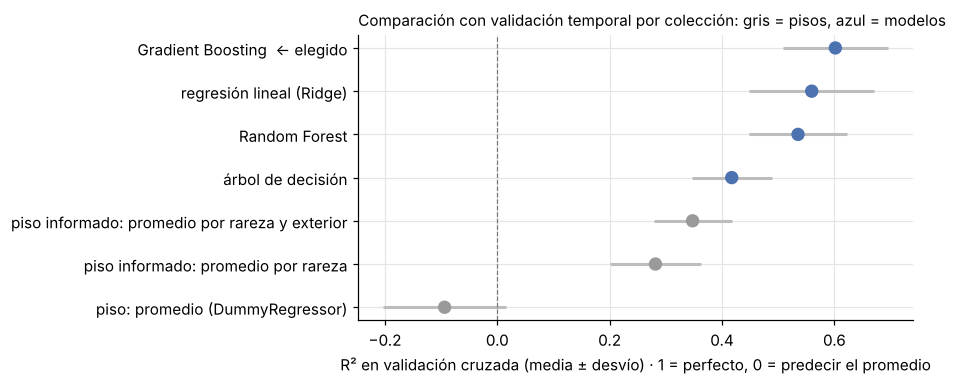

El elegido le gana al piso por 0.696 de R² y al mejor piso informado por 0.254.
Todos tienen sesgo positivo (el elegido +8.6, el piso +6.7): las colecciones más nuevas quedan más abajo de lo que el pasado hace esperar. Se vuelve a ver en 9.1.


In [11]:
t = pd.DataFrame(pisos + comparacion).sort_values("R²")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
colores = [AZUL if m in CANDIDATOS else GRIS for m in t["modelo"]]
ax.errorbar(t["R²"], range(len(t)), xerr=t["desvío R²"], fmt="none",
            ecolor="#BDBDBD", elinewidth=2, capsize=0)
ax.scatter(t["R²"], range(len(t)), c=colores, s=60, zorder=3)
ax.axvline(0, color="#777777", lw=0.8, ls="--")
ax.set_yticks(range(len(t)))
ax.set_yticklabels([f"{m}  ← elegido" if m == ELEGIDO else m for m in t["modelo"]])
ax.set_xlabel("R² en validación cruzada (media ± desvío) · 1 = perfecto, 0 = predecir el promedio")
ax.set_title("Comparación con validación temporal por colección: gris = pisos, azul = modelos",
             loc="left", fontsize=10)
plt.tight_layout(); plt.show()

print(f"El elegido le gana al piso por {res[ELEGIDO]['R²'] - PISO['R²']:.3f} de R² "
      f"y al mejor piso informado por {res[ELEGIDO]['R²'] - MEJOR_PISO['R²']:.3f}.")
print(f"Todos tienen sesgo positivo (el elegido {res[ELEGIDO]['sesgo']:+.1f}, el piso {PISO['sesgo']:+.1f}): "
      "las colecciones más nuevas quedan más abajo de lo que el pasado hace esperar. Se vuelve a ver en 9.1.")

**Cómo se lee.** Gradient Boosting tiene el mayor R² (0,602 ± 0,093) y le suma
0,042 de R² a la regresión lineal con un desvío de la diferencia de 0,020, ganando
en los cuatro pedazos: supera el ruido, y es el elegido. Random Forest y el árbol
solo quedan **por debajo** de la lineal.

**Qué quieren decir los números.** El elegido explica alrededor del **60 %** de la
variación del percentil en colecciones posteriores a las que vio. El mejor piso
informado (promedio por rareza y exterior) explica el 35 %. El promedio solo da un
R² negativo (−0,094): el promedio del pasado ni siquiera sirve como estimación para
las colecciones que vienen, que es el corrimiento de la sección 9.1 asomando desde
el piso.

**El cambio de métrica no cambió el modelo.** Con el MAE, la versión anterior de esta
entrega elegía también Gradient Boosting (0,91 puntos de mejora con un desvío de
0,53). Con el snapshot del 15/10 (2.012 filas), medido con MAE, la ventaja no
superaba el ruido y se quedaba la lineal: con cinco veces más filas, la evidencia
alcanza con cualquiera de las dos métricas.

**Qué puede ver Gradient Boosting que la lineal no.** La lineal suma un efecto por
columna. Los árboles pueden aprender **combinaciones**: que el origen pese distinto
según la rareza, o que ser souvenir «sin identificar» signifique escasez. La sección
8.2 muestra que las primeras preguntas del árbol son justamente la rareza y, dentro
de cada rama, el origen.

### 6.2 · ¿Qué pasa si los pedazos se arman de otra forma?

Es la pregunta de la consigna, medida. El mismo modelo elegido, con cuatro
formas de armar los pedazos, de la más optimista a la más parecida al uso:

- **al azar** (`KFold`): filas hermanas de los dos lados;
- **por skin base** (`GroupKFold` por `skin_id`): el mismo skin nunca queda de
  los dos lados, pero la misma colección sí;
- **por colección, sin orden** (`GroupKFold` por `collection`): lo que proponía la
  Entrega 2. Ninguna colección de los dos lados, pero se valida con colecciones
  de cualquier época;
- **por colección y en el tiempo** (la nuestra).

La diferencia de R² entre la primera y la última es el optimismo que traería una
validación al azar: un número más lindo que el real, sin ningún aviso. El sesgo
muestra lo que las otras tres esconden.

In [12]:
modelo_elegido = armar_modelo(CANDIDATOS[ELEGIDO])
esquemas = [
    evaluar("al azar (KFold)", modelo_elegido, cv=KFold(5, shuffle=True, random_state=SEMILLA)),
    evaluar("por skin base (GroupKFold)", modelo_elegido, cv=GroupKFold(5), g=train["skin_id"].astype(str)),
    evaluar("por colección, sin orden (GroupKFold)", modelo_elegido, cv=GroupKFold(5), g=grupos),
    evaluar("por colección y en el tiempo · la nuestra", modelo_elegido),
]
t_esq = tabla(esquemas).rename(columns={"modelo": "cómo se arman los pedazos"})
optimismo = esquemas[0]["R²"] - esquemas[-1]["R²"]
print(f"Con pedazos al azar el R² sale {optimismo:.3f} más alto que con la validación temporal "
      f"({esquemas[0]['R²']:.3f} contra {esquemas[-1]['R²']:.3f}), y el sesgo pasa de "
      f"{esquemas[-1]['sesgo']:+.1f} a {esquemas[0]['sesgo']:+.1f}: el corrimiento hacia las colecciones "
      "nuevas desaparece del número.")
t_esq

Con pedazos al azar el R² sale 0.068 más alto que con la validación temporal (0.670 contra 0.602), y el sesgo pasa de +8.6 a -0.0: el corrimiento hacia las colecciones nuevas desaparece del número.


,cómo se arman los pedazos,R²,desvío R²,MAE,sesgo
0,al azar (KFold),0.670,0.008,12.805,-0.035
1,por skin base (GroupKFold),0.606,0.035,14.015,0.142
2,"por colección, sin orden (GroupKFold)",0.581,0.070,14.242,0.043
3,por colección y en el tiempo · la nuestra,0.602,0.093,14.835,8.554


**Cómo se lee.** Al azar, el R² sale 0,068 más alto (0,670 contra 0,602) y con un
desvío casi nulo: un número lindo y estable que no corresponde al uso. Lo
interesante es que **el R² solo no alcanza** para ver el problema: por colección sin
orden da 0,581, apenas por debajo de la validación temporal. Lo que separa a la
validación temporal de las otras tres es el **sesgo**: +8,6 puntos contra ~0. Las
otras tres mezclan colecciones de todas las épocas y el corrimiento hacia las
colecciones nuevas se promedia y desaparece; la temporal es la única que lo deja a la
vista. Por eso el R² se informa siempre junto al sesgo.

## 7 · Las columnas que probamos

Con el modelo elegido y la misma validación, se saca **una columna por vez** y
se mide el R² sin ella. Si sacarla baja el R², la columna aporta. Esa
tabla es evidencia para todas las columnas.

**Regla para las dos columnas en duda** (`neg_log_p_item`, que dejó H4
inconclusa, y `origen`, que quedó en amarillo), escrita antes de medir:

1. Se prueban **las cuatro combinaciones**: las dos, sin una, sin la otra y sin
   ninguna. Sacarlas de a una no alcanza, porque comparten información: si una
   repite lo que dice la otra, sacar cualquiera de las dos sola no cambia nada,
   y eso no prueba que se puedan sacar las dos.
2. Una combinación es **aceptable** si su R² no baja respecto del de todas las
   columnas por más que el desvío de la diferencia (la regla en pares de la sección 6).
3. De las aceptables se queda **la que tiene menos columnas**; si empatan, la de
   mayor R².

Las demás columnas tienen respaldo en verde en la Entrega 2 y se quedan; su fila
en la tabla es evidencia.

In [13]:
completo = evaluar("todas las columnas", armar_modelo(CANDIDATOS[ELEGIDO]))
filas_abl = []
for c in COLUMNAS_MODELO:
    cols = [x for x in COLUMNAS_MODELO if x != c]
    r = evaluar(f"sin {c}", armar_modelo(CANDIDATOS[ELEGIDO], cols))
    p = comparar(completo, r)                      # dif > 0: sin la columna explica menos
    filas_abl.append({"columna": c, "R² con todas": completo["R²"], "R² sin ella": r["R²"],
                      "cuánto baja el R² al sacarla": p["dif"], "desvío de la diferencia": p["desvío dif"],
                      "pedazos en que baja": p["pedazos en que empeora"],
                      "lectura": ("aporta" if p["dif"] > p["desvío dif"] else
                                  "sacarla mejora" if -p["dif"] > p["desvío dif"] else "dentro del ruido")})
ablacion = pd.DataFrame(filas_abl).sort_values("cuánto baja el R² al sacarla", ascending=False)
print(f"R² con todas las columnas: {completo['R²']:.3f} ± {completo['desvío R²']:.3f}")
print("\nSacando una columna por vez:")
ablacion.round(3)

R² con todas las columnas: 0.602 ± 0.093

Sacando una columna por vez:


,columna,R² con todas,R² sin ella,cuánto baja el R² al sacarla,desvío de la diferencia,pedazos en que baja,lectura
0,rarity_orden,0.602,0.457,0.145,0.095,4,aporta
1,wear_orden,0.602,0.543,0.059,0.021,4,aporta
5,origen,0.602,0.543,0.059,0.035,4,aporta
6,neg_log_p_item,0.602,0.582,0.020,0.008,4,aporta
2,stattrak,0.602,0.591,0.011,0.006,4,aporta
3,souvenir,0.602,0.602,-0.001,0.003,2,dentro del ruido
4,weapon,0.602,0.620,-0.019,0.022,1,dentro del ruido


### Por qué las dos en duda se prueban juntas

El cruce de abajo lo muestra sin ninguna cuenta: `neg_log_p_item` tiene valor
**exactamente** cuando `origen` es "caja". La columna indicadora que agrega el
imputador ("este item no sale de una caja") es una copia de una de las columnas
del one-hot de `origen`.

In [14]:
pd.crosstab(df["origen"], df["neg_log_p_item"].notna().map({True: "tiene neg_log_p_item",
                                                             False: "nulo"}))

neg_log_p_item,nulo,tiene neg_log_p_item
origen,,
caja,0,4948
drop de mapa,3020,0
paquete souvenir,1176,0
sin identificar,859,0


In [15]:
EN_DUDA_A, EN_DUDA_B = COLUMNAS_EN_DUDA
combinaciones = {
    "las dos": [],
    f"sin {EN_DUDA_A}": [EN_DUDA_A],
    f"sin {EN_DUDA_B}": [EN_DUDA_B],
    "sin ninguna de las dos": [EN_DUDA_A, EN_DUDA_B],
}
filas_comb = []
for nombre, sacar in combinaciones.items():
    cols = [c for c in COLUMNAS_MODELO if c not in sacar]
    r = completo if not sacar else evaluar(nombre, armar_modelo(CANDIDATOS[ELEGIDO], cols))
    p = comparar(completo, r)
    filas_comb.append({"combinación": nombre, "columnas": len(cols), "R²": r["R²"],
                       "cuánto baja el R²": p["dif"], "desvío de la diferencia": p["desvío dif"],
                       "pedazos en que baja": p["pedazos en que empeora"],
                       "aceptable": p["dif"] <= p["desvío dif"], "_sacar": sacar})
combos = pd.DataFrame(filas_comb)
elegida = combos[combos["aceptable"]].sort_values(["columnas", "R²"], ascending=[True, False]).iloc[0]
SALEN = list(elegida["_sacar"])
COLUMNAS_FINALES = [c for c in COLUMNAS_MODELO if c not in SALEN]

print("aceptable = no baja el R² de todas las columnas por más que el desvío de la diferencia")
print(f"combinación elegida: {elegida['combinación']}  (R² {elegida['R²']:.3f})")
print("salen:", SALEN or "ninguna")
print("columnas finales:", COLUMNAS_FINALES)
combos.drop(columns="_sacar").round(3)

aceptable = no baja el R² de todas las columnas por más que el desvío de la diferencia
combinación elegida: las dos  (R² 0.602)
salen: ninguna
columnas finales: ['rarity_orden', 'wear_orden', 'stattrak', 'souvenir', 'weapon', 'origen', 'neg_log_p_item']


,combinación,columnas,R²,cuánto baja el R²,desvío de la diferencia,pedazos en que baja,aceptable
0,las dos,7,0.602,0.000,0.000,0,True
1,sin neg_log_p_item,6,0.582,0.020,0.008,4,False
2,sin origen,6,0.543,0.059,0.035,4,False
3,sin ninguna de las dos,5,0.417,0.185,0.069,4,False


**Cómo se lee.** Ninguna combinación con menos columnas es aceptable. Sacar
`neg_log_p_item` baja el R² 0,020 con un desvío de la diferencia de 0,008, en los
cuatro pedazos; sacar `origen` lo baja 0,059; sacar las dos, 0,185 (de 0,602 a 0,417).
Se quedan las dos: **7 columnas**.

**Por qué cambió respecto del 15/10.** Con 2.012 filas (y medido con MAE), sacar
`neg_log_p_item` empeoraba casi lo mismo, pero con un desvío más grande que el efecto:
no se podía afirmar, y salía. Con 10.003 filas el ruido bajó. Con esto se cierra la
H4, que la Entrega 2 dejó en amarillo: la probabilidad de drop **aporta, poco**
(2 puntos de R²).

**Coincide con el dominio.** Las dos columnas no dicen exactamente lo mismo:

- `origen` sólo dice "caja"; `neg_log_p_item` dice, **dentro** de las de caja, qué
  tan difícil es sacar ese ítem en particular.
- `origen` distingue algo que `neg_log_p_item` no ve: las souvenir de paquete de
  torneo, abundantes y baratas, de las souvenir "sin identificar", raras y caras.
  Por eso sacar `origen` cuesta tres veces más que sacar `neg_log_p_item`.

**Lo que dice la tabla de una columna por vez.** `rarity_orden` es la que más aporta
(sacarla baja el R² 0,145). `stattrak` aporta poco pero en los cuatro pedazos
(0,011 ± 0,006). `souvenir` queda dentro del ruido: con `origen` adentro, casi todo lo
que dice ya está dicho (las souvenir son justamente las de paquete y las "sin
identificar"). Se queda porque su efecto, medido en pares en la Entrega 2, es verde
y no le cuesta nada al modelo. Sacar `weapon` sube un poco el R² (0,019), pero dentro
del ruido (desvío 0,022): se revisa en la sección 8.

### `antiguedad_col_dias`: la regla y el argumento

En la Entrega 2 salió por argumento: para un skin recién lanzado vale casi cero,
y ninguna colección del entrenamiento es tan nueva. Con la validación temporal
ahora se puede **medir** una parte de ese problema, porque en cada pedazo se
valida con colecciones más nuevas que todas las del entrenamiento: el modelo
tiene que extrapolar hacia edades que no vio.

Se le aplica la misma regla que a las columnas en duda: **entra sólo si con ella el
R² sube por más que el desvío**. Y se mira el sesgo, porque es justo lo que esta
columna podría corregir.

In [16]:
con_antig = COLUMNAS_FINALES + ["antiguedad_col_dias"]
sin_a = evaluar("sin antiguedad_col_dias", armar_modelo(CANDIDATOS[ELEGIDO], COLUMNAS_FINALES))
con_a = evaluar("con antiguedad_col_dias", armar_modelo(CANDIDATOS[ELEGIDO], con_antig))
p_antig = comparar(con_a, sin_a)                 # dif > 0: con la columna se explica más
ENTRA_ANTIGUEDAD = p_antig["dif"] > p_antig["desvío dif"]

edad_tr = train["antiguedad_col_dias"]
print(f"edades en el entrenamiento: de {edad_tr.min() / 365:.1f} a {edad_tr.max() / 365:.1f} años; "
      "un skin recién lanzado tiene 0.")
print(f"con la columna el R² cambia en {p_antig['dif']:+.3f} en promedio, con un desvío de la "
      f"diferencia de {p_antig['desvío dif']:.3f} (sube en {p_antig['pedazos en que empeora']} de "
      f"{len(PEDAZOS)} pedazos). El sesgo pasa de {sin_a['sesgo']:+.1f} a {con_a['sesgo']:+.1f}.")
if ENTRA_ANTIGUEDAD:
    COLUMNAS_FINALES = con_antig
    print("Sube el R² por más que el desvío: entra.")
else:
    print("La mejora del R² no supera el desvío: no entra, y coincide con el argumento de la Entrega 2.")
    if abs(con_a["sesgo"]) < abs(sin_a["sesgo"]):
        print("Lo que sí corrige es el sesgo; queda anotado para la Entrega 4 (sección 11).")
    elif ELEGIDO != REFERENCIA:
        print("Y con este modelo tampoco corrige el sesgo: un árbol no puede extrapolar a edades que "
              "nunca vio (un skin nuevo tiene 0 días), así que las colecciones nuevas quedan en la "
              "misma hoja que las más jóvenes del entrenamiento. Queda anotado para la Entrega 4.")
    else:
        print("Y tampoco corrige el sesgo. Queda anotado para la Entrega 4.")
print("columnas finales:", COLUMNAS_FINALES)
tabla([sin_a, con_a])[["modelo", "R²", "desvío R²", "MAE", "sesgo"]]

edades en el entrenamiento: de 3.5 a 13.2 años; un skin recién lanzado tiene 0.
con la columna el R² cambia en -0.374 en promedio, con un desvío de la diferencia de 0.547 (sube en 2 de 4 pedazos). El sesgo pasa de +8.6 a +13.0.
La mejora del R² no supera el desvío: no entra, y coincide con el argumento de la Entrega 2.
Y con este modelo tampoco corrige el sesgo: un árbol no puede extrapolar a edades que nunca vio (un skin nuevo tiene 0 días), así que las colecciones nuevas quedan en la misma hoja que las más jóvenes del entrenamiento. Queda anotado para la Entrega 4.
columnas finales: ['rarity_orden', 'wear_orden', 'stattrak', 'souvenir', 'weapon', 'origen', 'neg_log_p_item']


,modelo,R²,desvío R²,MAE,sesgo
0,sin antiguedad_col_dias,0.602,0.093,14.835,8.554
1,con antiguedad_col_dias,0.227,0.603,18.825,13.002


**Cómo se lee.** Con la antigüedad el R² medio no sube: se derrumba de 0,602 a 0,227,
con un desvío enorme (0,603). En dos pedazos ayuda y en los otros dos el modelo se
equivoca muchísimo. Es lo que se espera de una columna que en el futuro toma valores
que el entrenamiento nunca vio: el R² lo castiga con fuerza porque esos errores son
grandes, y el error cuadrático los pesa más. El argumento de la Entrega 2 queda
medido: no entra.

## 8 · El ajuste de hiperparámetros del elegido

Grilla sobre el modelo elegido, con las columnas finales y la misma
validación temporal por colección. `GridSearchCV` se queda con la combinación de
**mayor R² medio** (`refit="r2"`). Se muestra **la tabla completa**, no sólo el
ganador, y se compara contra la versión por defecto con la regla en pares.

**Clases desparejas:** no aplica, el objetivo es un número. Además el
percentil está repartido parejo por construcción: no hay una zona del objetivo
con pocas filas.

In [17]:
P = "regressor__modelo__"
GRILLAS = {
    "regresión lineal (Ridge)": {P + "alpha": [0.01, 0.1, 1, 3, 10, 30, 100]},
    "árbol de decisión": {P + "max_depth": [3, 5, 8, 12, None],
                          P + "min_samples_leaf": [1, 5, 10, 20, 40]},
    "Random Forest": {P + "max_depth": [None, 8, 16],
                      P + "min_samples_leaf": [1, 3, 5, 10],
                      P + "max_features": [1.0, 0.5, "sqrt"]},
    "Gradient Boosting": {P + "learning_rate": [0.03, 0.1],
                          P + "max_leaf_nodes": [15, 31],
                          P + "min_samples_leaf": [10, 20, 40],
                          P + "loss": ["squared_error", "absolute_error"]},
}

# refit="r2": de la grilla se queda la combinación con el mayor R² medio.
busqueda = GridSearchCV(armar_modelo(CANDIDATOS[ELEGIDO], COLUMNAS_FINALES), GRILLAS[ELEGIDO],
                        cv=PEDAZOS, scoring=METRICAS, refit="r2", n_jobs=1)
busqueda.fit(X_tr, y_tr)

cv = pd.DataFrame(busqueda.cv_results_)
grilla = pd.DataFrame({
    **{k.replace(P, ""): cv["param_" + k].map(lambda v: "None" if v is None or v != v else str(v))
       for k in GRILLAS[ELEGIDO]},
    "R²": cv["mean_test_r2"], "desvío R²": cv["std_test_r2"],
    "MAE": -cv["mean_test_mae"], "sesgo": cv["mean_test_sesgo"], "puesto": cv["rank_test_r2"],
}).sort_values("puesto").round(3)

por_defecto = evaluar("por defecto", armar_modelo(CANDIDATOS[ELEGIDO], COLUMNAS_FINALES))
i_mejor = busqueda.best_index_
R2_CV = float(busqueda.best_score_)
DESVIO_CV = float(cv.loc[i_mejor, "std_test_r2"])
MAE_CV = float(-cv.loc[i_mejor, "mean_test_mae"])
SESGO_CV = float(cv.loc[i_mejor, "mean_test_sesgo"])
ajustado = {"_r2_por_pedazo": np.array([cv.loc[i_mejor, f"split{i}_test_r2"]
                                         for i in range(len(PEDAZOS))])}
p_ajuste = comparar(ajustado, por_defecto)      # dif > 0: el ajustado explica más
mejora_ajuste = p_ajuste["dif"]
print(f"{len(grilla)} combinaciones x {len(PEDAZOS)} pedazos")
print("mejores hiperparámetros:", {k.replace(P, ""): v for k, v in busqueda.best_params_.items()})
print(f"R² por defecto {por_defecto['R²']:.3f} -> ajustado {R2_CV:.3f} ± {DESVIO_CV:.3f} "
      f"(sube {mejora_ajuste:+.3f}, desvío de la diferencia {p_ajuste['desvío dif']:.3f})")
print(f"en puntos de percentil, el ajustado erra {MAE_CV:.2f} en promedio (MAE), con sesgo {SESGO_CV:+.2f}")
if mejora_ajuste > p_ajuste["desvío dif"]:
    print("El ajuste sube el R² por más que el desvío de la diferencia: vale la pena.")
else:
    print("La mejora del ajuste no supera el desvío de la diferencia: el ajuste casi no cambia el resultado.")
grilla

24 combinaciones x 4 pedazos
mejores hiperparámetros: {'learning_rate': 0.1, 'loss': 'squared_error', 'max_leaf_nodes': 31, 'min_samples_leaf': 40}
R² por defecto 0.602 -> ajustado 0.614 ± 0.103 (sube +0.013, desvío de la diferencia 0.012)
en puntos de percentil, el ajustado erra 14.62 en promedio (MAE), con sesgo +8.47
El ajuste sube el R² por más que el desvío de la diferencia: vale la pena.


,learning_rate,max_leaf_nodes,min_samples_leaf,loss,R²,desvío R²,MAE,sesgo,puesto
17,0.1,31,40,squared_error,0.614,0.103,14.622,8.471,1
14,0.1,15,40,squared_error,0.608,0.110,14.831,8.965,2
20,0.1,15,40,absolute_error,0.606,0.131,14.454,9.384,3
5,0.03,31,40,squared_error,0.605,0.109,14.987,8.908,4
13,0.1,15,20,squared_error,0.604,0.094,14.921,8.857,5
23,0.1,31,40,absolute_error,0.604,0.134,14.388,9.244,6
16,0.1,31,20,squared_error,0.602,0.093,14.835,8.554,7
19,0.1,15,20,absolute_error,0.601,0.123,14.570,9.335,8
12,0.1,15,10,squared_error,0.601,0.092,14.969,8.656,9
4,0.03,31,20,squared_error,0.598,0.101,15.203,8.914,10


**Cómo se lee.** El ajuste sube el R² de 0,602 a 0,614, con un desvío de la diferencia
de 0,012: supera el ruido, pero por muy poco, así que se lo toma como una mejora chica
y no como un cambio de modelo.

**Una consecuencia directa del cambio de métrica.** Con el R², la grilla elige
`loss="squared_error"`; con el MAE, la versión anterior elegía `absolute_error`. No es
casualidad: el R² está hecho con el error cuadrático, así que conviene entrenar
minimizando el error cuadrático. La métrica con la que se elige decide también qué
pérdida le conviene al modelo. En MAE el ajustado erra 14,6 puntos, casi igual que
antes: la elección cambia la pérdida, no la calidad general.

### `weapon`, revisada con el ajuste

En la tabla de la sección 7, sacar `weapon` subía un poco el R², aunque dentro
del ruido. Son 34 columnas de one-hot, y muchas armas tienen pocos skins: un modelo
con poca regularización puede ajustarse de más a las armas de las colecciones que
vio. Con los hiperparámetros elegidos se vuelve a medir, con y sin la columna.

In [18]:
mejor_reg = busqueda.best_estimator_.regressor.named_steps["modelo"]
sin_weapon = [c for c in COLUMNAS_FINALES if c != "weapon"]
con_w = evaluar("con weapon (ajustado)", armar_modelo(mejor_reg, COLUMNAS_FINALES))
sin_w = evaluar("sin weapon (ajustado)", armar_modelo(mejor_reg, sin_weapon))
p_w = comparar(con_w, sin_w)                     # dif > 0: sin weapon se explica menos
print(f"con los hiperparámetros elegidos, sacar weapon cambia el R² en {-p_w['dif']:+.3f} "
      f"(desvío de la diferencia {p_w['desvío dif']:.3f})")
if -p_w["dif"] > p_w["desvío dif"]:
    print("Sacarla sube el R² por más que el desvío: weapon debería salir. Revisar la decisión.")
elif p_w["dif"] > p_w["desvío dif"]:
    print("Sacarla baja el R² por más que el desvío: weapon aporta y se queda.")
else:
    print("La diferencia queda adentro del desvío: weapon se queda, con el respaldo de H1 (verde).")
tabla([con_w, sin_w])[["modelo", "R²", "desvío R²", "MAE", "sesgo"]]

con los hiperparámetros elegidos, sacar weapon cambia el R² en +0.004 (desvío de la diferencia 0.019)
La diferencia queda adentro del desvío: weapon se queda, con el respaldo de H1 (verde).


,modelo,R²,desvío R²,MAE,sesgo
0,con weapon (ajustado),0.614,0.103,14.622,8.471
1,sin weapon (ajustado),0.618,0.114,14.614,8.529


### 8.2 · Los árboles y las muchas columnas (lo que marcó el profesor)

> «Revisen bien qué modelo eligen: con un árbol se pueden generar muchas
> columnas, y hay que elegir bien cuál es la columna representativa, que no sea
> el precio.»

**Muchas columnas.** Con one-hot, `weapon` se convierte en una columna 0/1 por
arma. Un árbol sólo puede preguntar por una columna a la vez («¿es AK-47, sí o
no?»): para separar diez armas caras necesita diez preguntas, y la importancia
del arma queda repartida en muchas columnas chicas. La alternativa es darle
**una sola columna por variable categórica** (`OrdinalEncoder`): cada arma
recibe un número —un código, que no sale del precio— y el árbol puede agruparlas
con cortes del tipo «¿código de arma ≤ 12?».

Se prueba en las tres familias de árboles, con las columnas finales (7, después
de la sección 7) y la misma validación temporal, con las dos codificaciones. Cada
variante se compara con el modelo elegido ya ajustado usando la **misma regla en
pares**, en R². Si alguna le ganara por más que el desvío de la diferencia, la
elección habría que revisarla.

Como el elegido ya es Gradient Boosting, la fila «Gradient Boosting, one-hot» es el mismo modelo con los valores por defecto: su diferencia contra el elegido es lo que aportó el ajuste.

In [19]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import export_text


def preprocesamiento_ordinal(columnas):
    # El mismo preprocesamiento, pero una sola columna (un código) por variable categórica.
    ct = preprocesamiento(columnas)
    pasos = [(n, OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
              if n == "categoricas" else t, c) for n, t, c in ct.transformers]
    return ColumnTransformer(pasos, remainder="drop")


def armar_modelo_ordinal(regresor, columnas):
    pipe = Pipeline([("prep", preprocesamiento_ordinal(columnas)), ("modelo", clone(regresor))])
    return TransformedTargetRegressor(regressor=pipe, func=np.asarray,
                                      inverse_func=RECORTE, check_inverse=False)


n_oh = len(preprocesamiento(COLUMNAS_FINALES).fit(X_tr).get_feature_names_out())
n_or = len(preprocesamiento_ordinal(COLUMNAS_FINALES).fit(X_tr).get_feature_names_out())
print(f"{len(COLUMNAS_FINALES)} columnas del CSV -> one-hot: {n_oh} columnas | "
      f"una por categórica: {n_or} columnas (weapon tiene {X_tr['weapon'].nunique()} armas)\n")

filas_arb, ARBOL_GANA = [], []
for nombre in ["árbol de decisión", "Random Forest", "Gradient Boosting"]:
    oh = evaluar(f"{nombre} · one-hot", armar_modelo(clone(CANDIDATOS[nombre]), COLUMNAS_FINALES))
    orr = evaluar(f"{nombre} · una por categórica", armar_modelo_ordinal(CANDIDATOS[nombre], COLUMNAS_FINALES))
    for cod, r in (("one-hot", oh), ("una por categórica", orr)):
        c = comparar(r, ajustado)                # dif > 0: la variante explica más que el elegido
        gana = c["dif"] > c["desvío dif"]
        if gana:
            ARBOL_GANA.append(f"{nombre} ({cod})")
        filas_arb.append({"familia": nombre, "codificación": cod,
                          "columnas que ve": n_oh if cod == "one-hot" else n_or,
                          "R²": r["R²"], "MAE": r["MAE"], "sesgo": r["sesgo"],
                          "R² que suma contra el elegido": c["dif"], "desvío de la diferencia": c["desvío dif"],
                          "resultado": "le gana al elegido" if gana else "no alcanza"})
arboles_codificacion = pd.DataFrame(filas_arb).round(3)
RESUMEN_ARBOLES = (f"{ARBOL_GANA} le ganan al elegido: revisar la elección" if ARBOL_GANA else
                   "ninguna variante le gana al elegido por más que el desvío")
print(f"elegido ajustado: {ELEGIDO}, R² {R2_CV:.3f}")
print("árboles con una columna por categórica:", RESUMEN_ARBOLES)
arboles_codificacion

7 columnas del CSV -> one-hot: 44 columnas | una por categórica: 8 columnas (weapon tiene 34 armas)



elegido ajustado: Gradient Boosting, R² 0.614
árboles con una columna por categórica: ninguna variante le gana al elegido por más que el desvío


,familia,codificación,columnas que ve,R²,MAE,sesgo,R² que suma contra el elegido,desvío de la diferencia,resultado
0,árbol de decisión,one-hot,44,0.417,16.666,8.404,-0.197,0.044,no alcanza
1,árbol de decisión,una por categórica,8,0.383,17.105,8.374,-0.231,0.023,no alcanza
2,Random Forest,one-hot,44,0.535,15.401,8.505,-0.079,0.040,no alcanza
3,Random Forest,una por categórica,8,0.507,15.907,8.609,-0.107,0.027,no alcanza
4,Gradient Boosting,one-hot,44,0.602,14.835,8.554,-0.013,0.012,no alcanza
5,Gradient Boosting,una por categórica,8,0.587,15.078,8.865,-0.027,0.024,no alcanza


**La columna representativa.** Se entrena un árbol chico (profundidad 4, al
menos 20 skins por hoja), con una columna por categórica, sobre todo el
entrenamiento, y se muestran sus primeras preguntas. La primera pregunta es la
columna que más separa los precios: tiene que ser un atributo del skin, nunca el
precio ni algo calculado a partir de él. Los cortes de las columnas numéricas
están en unidades escaladas (desvíos), porque el pipeline escala antes del
árbol: lo que importa es **por qué columna pregunta**.

In [20]:
arbol = armar_modelo_ordinal(DecisionTreeRegressor(max_depth=4, min_samples_leaf=20,
                                                   random_state=SEMILLA), COLUMNAS_FINALES).fit(X_tr, y_tr)
pipe_arbol = arbol.regressor_
nombres_arbol = [n.split("__", 1)[1] for n in pipe_arbol.named_steps["prep"].get_feature_names_out()]
modelo_arbol = pipe_arbol.named_steps["modelo"]
RAIZ = nombres_arbol[modelo_arbol.tree_.feature[0]]
print(f"primera pregunta del árbol: {RAIZ}\n")
print(export_text(modelo_arbol, feature_names=nombres_arbol, max_depth=2, decimals=2))
print("cuánto usa cada columna el árbol (sobre el entrenamiento):")
print(pd.Series(modelo_arbol.feature_importances_, index=nombres_arbol)
        .sort_values(ascending=False).round(3).to_string())
assert not PROHIBIDAS & set(nombres_arbol), "una columna del precio entró al árbol"
print("\nNinguna columna del árbol sale del precio ni de los listings: la representativa es "
      f"{RAIZ}, un atributo que existe el día que sale el skin.")

primera pregunta del árbol: rarity_orden

|--- rarity_orden <= 0.81
|   |--- origen <= 2.50
|   |   |--- rarity_orden <= 0.10
|   |   |   |--- truncated branch of depth 2
|   |   |--- rarity_orden >  0.10
|   |   |   |--- truncated branch of depth 2
|   |--- origen >  2.50
|   |   |--- wear_orden <= -0.29
|   |   |   |--- truncated branch of depth 2
|   |   |--- wear_orden >  -0.29
|   |   |   |--- truncated branch of depth 2
|--- rarity_orden >  0.81
|   |--- rarity_orden <= 1.52
|   |   |--- missingindicator_neg_log_p_item <= 0.15
|   |   |   |--- truncated branch of depth 2
|   |   |--- missingindicator_neg_log_p_item >  0.15
|   |   |   |--- truncated branch of depth 2
|   |--- rarity_orden >  1.52
|   |   |--- origen <= 0.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- origen >  0.50
|   |   |   |--- truncated branch of depth 2

cuánto usa cada columna el árbol (sobre el entrenamiento):
rarity_orden                       0.653
origen                             0.187


## 9 · La prueba, mirada una sola vez

Todo lo anterior se eligió con validación cruzada sobre el entrenamiento. La
búsqueda ya reentrenó el modelo elegido, con los mejores hiperparámetros, sobre
**todo** el entrenamiento. Ahora se mide **una vez** sobre las colecciones más
nuevas. Después de esta celda no se cambia nada del modelo.

**Lo que se decide antes de mirar.** Pase lo que pase en la prueba, el modelo
para la aplicación de la Entrega 4 es el mismo —mismas columnas, mismo modelo,
mismos hiperparámetros— reentrenado con **todas** las filas, incluidas las de la
prueba (sección 12). No es elegir con la prueba: es la práctica estándar de usar
todos los datos una vez que el número ya se midió. Y es importante en este caso,
porque las colecciones más nuevas son las que más se parecen a lo que va a
salir.

In [21]:
modelo_final = busqueda.best_estimator_
pred_te = modelo_final.predict(X_te)
test["predicho"] = pred_te
test["error"] = test["predicho"] - test["percentil"]

piso_te = armar_modelo(DummyRegressor(strategy="mean")).fit(X_tr, y_tr).predict(X_te)
mejor_piso_cols = ("rarity", "wear") if "exterior" in MEJOR_PISO["modelo"] else ("rarity",)
piso_inf_te = MediaPorGrupo(mejor_piso_cols).fit(X_tr, y_tr).predict(X_te)

R2_TEST = r2_score(y_te, pred_te)
MAE_TEST = mean_absolute_error(y_te, pred_te)
SESGO_TEST = sesgo(y_te, pred_te)
R2_PISO_TEST = r2_score(y_te, piso_te)
R2_PISO_INF_TEST = r2_score(y_te, piso_inf_te)
SESGO_PISO_TEST = sesgo(y_te, piso_te)
resultado_test = pd.DataFrame([
    {"": "piso: promedio", "R²": R2_PISO_TEST,
     "MAE": mean_absolute_error(y_te, piso_te), "sesgo": SESGO_PISO_TEST},
    {"": MEJOR_PISO["modelo"], "R²": R2_PISO_INF_TEST,
     "MAE": mean_absolute_error(y_te, piso_inf_te), "sesgo": sesgo(y_te, piso_inf_te)},
    {"": f"modelo final: {ELEGIDO}", "R²": R2_TEST, "MAE": MAE_TEST, "sesgo": SESGO_TEST},
]).round(3)

print(f"prueba: {len(test)} filas de {test['collection'].nunique()} colecciones que el modelo nunca vio")
print(f"R² en validación cruzada: {R2_CV:.3f} ± {DESVIO_CV:.3f} | R² en la prueba: {R2_TEST:.3f}")
print(f"MAE en validación cruzada: {MAE_CV:.2f} | MAE en la prueba: {MAE_TEST:.2f} (puntos de percentil)")
print(f"sesgo en validación cruzada: {SESGO_CV:+.2f} | sesgo en la prueba: {SESGO_TEST:+.2f}")
print(f"mediana del percentil: entrenamiento {y_tr.median():.1f} | prueba {y_te.median():.1f}")
if R2_TEST < R2_CV - 2 * DESVIO_CV:
    print("La prueba sale bastante peor que la validación (más de dos desvíos de R²). La validación "
          "temporal ya mostraba el sentido del error (sesgo positivo); en la prueba es más grande.")
if SESGO_PISO_TEST > 5:
    print(f"Hasta el piso, que no mira ninguna columna, se pasa por {SESGO_PISO_TEST:+.1f} puntos: las "
          "colecciones nuevas están, en conjunto, más abajo en el mercado que las establecidas. "
          "Es un corrimiento del objetivo, no un error de una columna (ver 9.1).")
resultado_test

prueba: 2075 filas de 16 colecciones que el modelo nunca vio
R² en validación cruzada: 0.614 ± 0.103 | R² en la prueba: 0.272
MAE en validación cruzada: 14.62 | MAE en la prueba: 23.44 (puntos de percentil)
sesgo en validación cruzada: +8.47 | sesgo en la prueba: +22.59
mediana del percentil: entrenamiento 50.0 | prueba 27.0
La prueba sale bastante peor que la validación (más de dos desvíos de R²). La validación temporal ya mostraba el sentido del error (sesgo positivo); en la prueba es más grande.
Hasta el piso, que no mira ninguna columna, se pasa por +12.7 puntos: las colecciones nuevas están, en conjunto, más abajo en el mercado que las establecidas. Es un corrimiento del objetivo, no un error de una columna (ver 9.1).


,,R²,MAE,sesgo
0,piso: promedio,-0.149,31.938,12.707
1,piso informado: promedio por rareza y exterior,0.308,23.692,11.274
2,modelo final: Gradient Boosting,0.272,23.442,22.594


In [22]:
def _r2_grupo(g):
    return r2_score(g["percentil"], g["predicho"]) if len(g) > 1 else np.nan


por_coleccion = (test.assign(error_abs=test["error"].abs())
                     .groupby("collection")
                     .agg(lanzamiento=("collection_release", "first"),
                          filas=("percentil", "size"),
                          MAE=("error_abs", "mean"), sesgo=("error", "mean")))
por_coleccion["R²"] = test.groupby("collection")[["percentil", "predicho"]].apply(_r2_grupo)
por_coleccion = por_coleccion.sort_values("R²")[["lanzamiento", "filas", "R²", "MAE", "sesgo"]]
por_coleccion["lanzamiento"] = por_coleccion["lanzamiento"].dt.strftime("%Y-%m-%d")
por_coleccion[["R²", "MAE", "sesgo"]] = por_coleccion[["R²", "MAE", "sesgo"]].round(3)
print("La prueba, colección por colección: ¿es pareja o la arrastra una sola?")
print(f"colecciones con sesgo positivo (el modelo las pone más arriba): "
      f"{(por_coleccion['sesgo'] > 0).sum()} de {len(por_coleccion)}")
print(f"colecciones con R² negativo (peor que su propio promedio): "
      f"{(por_coleccion['R²'] < 0).sum()} de {len(por_coleccion)}")
por_coleccion

La prueba, colección por colección: ¿es pareja o la arrastra una sola?
colecciones con sesgo positivo (el modelo las pone más arriba): 16 de 16
colecciones con R² negativo (peor que su propio promedio): 4 de 16


,lanzamiento,filas,R²,MAE,sesgo
collection,,,,,
The Overpass 2024 Collection,2024-10-02,119,-0.334,29.496,29.463
The Genesis Collection,2025-09-16,151,-0.257,30.552,30.033
The Train 2025 Collection,2025-03-31,110,-0.125,29.806,28.799
The Dead Hand Collection,2026-03-11,178,-0.059,27.149,26.865
The Boreal Collection,2025-03-31,165,0.040,28.957,28.032
The Achroma Collection,2026-01-21,114,0.084,28.258,27.109
The Sport & Field Collection,2024-10-02,73,0.147,25.693,25.300
The Radiant Collection,2025-03-31,164,0.211,27.348,26.381
The Harlequin Collection,2026-01-21,127,0.252,25.013,24.543


### 9.1 · Por qué la prueba sale peor: el mercado de las colecciones nuevas

En R², el modelo pasa de 0,614 en la validación a **0,272 en la prueba**, y en la
prueba queda **por debajo del piso informado** (0,308). La prueba no sale peor por
una colección rara: el sesgo es positivo en **las 16** colecciones, y el piso, que no
mira ninguna columna, también se pasa. El R² lo castiga dos veces: el modelo ordena
razonablemente bien dentro de varias colecciones (Gallery 0,91, Fever 0,79), pero
pone a casi todas más arriba de lo que están, y ese corrimiento suma al error
cuadrático. Hay dos causas, y las dos son del dominio.

**1 · Las colecciones nuevas están más abajo en el mercado.** Una colección
recién lanzada se consigue todas las semanas: sus cajas se abren y sus skins
caen al jugar, así que hay mucha oferta. Las viejas salen del pool de drops y su
oferta deja de crecer. El modelo aprende las posiciones del **mercado
establecido** y pone a los skins nuevos más arriba de donde están hoy. La
validación temporal ya lo mostraba (sesgo positivo en todos los modelos y en el
piso), pero la prueba es más nueva todavía que cualquier pedazo de validación.

**2 · "Drop de mapa" cambió de significado.** En el entrenamiento, las
colecciones que no salen de una caja son colecciones de mapa viejas, que ya no
caen, y son caras. En la prueba son, en su mayoría, las del **Armory**, la
tienda de pases que CS2 sumó en octubre de 2024: se consiguen con el pase y
abundan. Entre la última colección de mapa del entrenamiento (abril de 2023) y la
primera de la prueba (octubre de 2024) no hay ninguna. El modelo no pudo ver ese
mecanismo, porque no existía en los datos con los que aprendió. Las dos tablas
de abajo lo muestran: el sesgo en "drop de mapa" es de más de 30 puntos.

**Qué se hace con esto.** No se corrige el modelo mirando la prueba, porque eso
la convertiría en entrenamiento. Se declara, y el modelo de la Entrega 4 se
reentrena con todas las colecciones, incluidas las del Armory (sección 12).

In [23]:
corrimiento = pd.DataFrame({
    "filas entrenamiento": train.groupby("origen").size(),
    "percentil mediano entrenamiento": train.groupby("origen")["percentil"].median(),
    "filas prueba": test.groupby("origen").size(),
    "percentil mediano prueba": test.groupby("origen")["percentil"].median(),
    "sesgo del modelo en la prueba": test.groupby("origen")["error"].mean(),
}).round(1)

mapa = (pd.concat([train.assign(lado="entrenamiento"), test.assign(lado="prueba")])
          .query("origen == 'drop de mapa'")
          .groupby("lado")
          .agg(colecciones=("collection", "nunique"), filas=("collection", "size"),
               primera=("collection_release", "min"), ultima=("collection_release", "max")))
mapa[["primera", "ultima"]] = mapa[["primera", "ultima"]].apply(lambda s: s.dt.strftime("%Y-%m-%d"))
print("Las colecciones 'drop de mapa' de cada lado:")
print(mapa.to_string())
print("\nPercentil y sesgo por origen:")
corrimiento

Las colecciones 'drop de mapa' de cada lado:
               colecciones  filas     primera      ultima
lado                                                     
entrenamiento           38   1893  2013-08-14  2023-04-25
prueba                  13   1127  2024-10-02  2026-07-08

Percentil y sesgo por origen:


,filas entrenamiento,percentil mediano entrenamiento,filas prueba,percentil mediano prueba,sesgo del modelo en la prueba
origen,,,,,
caja,4542,45.7,406,24.1,11.2
drop de mapa,1893,50.9,1127,9.3,31.6
paquete souvenir,1063,48.2,113,23.8,26.3
sin identificar,430,87.8,429,78.8,8.8


## 10 · El modelo final, leído

### 10.1 · Real contra predicho

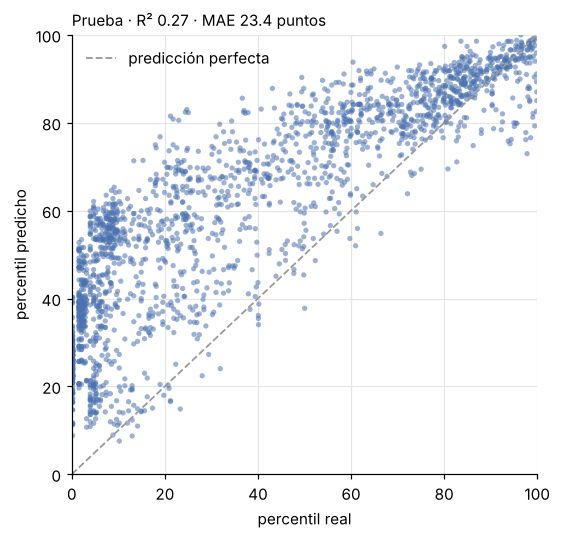

In [24]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(test["percentil"], test["predicho"], s=12, alpha=0.55, color=AZUL, edgecolors="none")
ax.plot([0, 100], [0, 100], color=GRIS, lw=1.2, ls="--", label="predicción perfecta")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("percentil real"); ax.set_ylabel("percentil predicho")
ax.set_title(f"Prueba · R² {R2_TEST:.2f} · MAE {MAE_TEST:.1f} puntos", loc="left", fontsize=10)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

### 10.2 · En qué tramo del objetivo se erra más

La pregunta es si el error es parejo o se concentra. Abajo, el MAE y el sesgo
por tramo del percentil real. Si el sesgo es positivo en los tramos bajos, son
skins baratos que el modelo pone más arriba: el corrimiento de la sección 9.1.

**Por qué acá el MAE y no el R².** Dentro de un tramo de 10 puntos el percentil real
casi no varía, así que el R² del tramo divide por una variación casi nula y no
significa nada. Para la pregunta "cuánto erra en esta zona" la lectura correcta es
el error en puntos (MAE) y su dirección (sesgo). El R² sigue siendo la métrica de
elección; esto es lectura del modelo ya elegido.

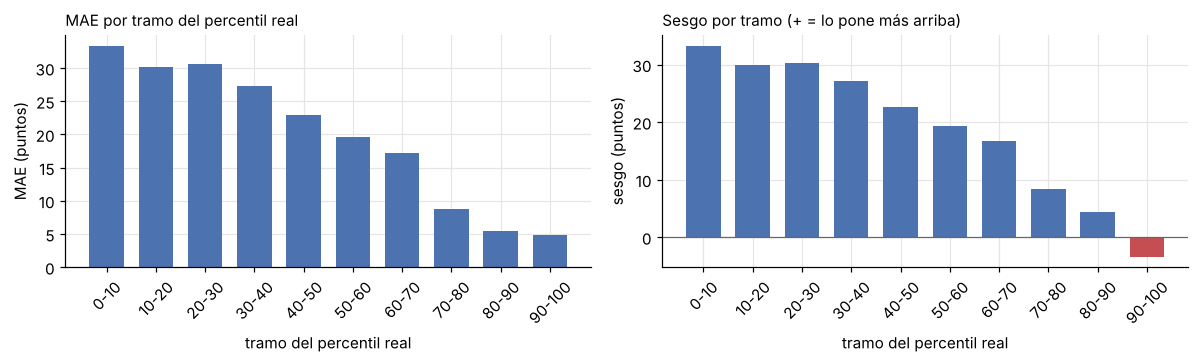

tramo con más error: 0-10 (MAE 33.3) | tramo con menos error: 90-100 (MAE 4.8)


,filas,MAE,sesgo
tramo,,,
0-10,723,33.31,33.31
10-20,171,30.18,29.97
20-30,174,30.64,30.33
30-40,128,27.31,27.18
40-50,107,22.98,22.54
50-60,148,19.65,19.33
60-70,118,17.12,16.66
70-80,166,8.70,8.30
80-90,189,5.39,4.30


In [25]:
TRAMOS = [f"{a}-{a + 10}" for a in range(0, 100, 10)]
test["tramo"] = pd.cut(test["percentil"], bins=range(0, 101, 10), labels=TRAMOS, include_lowest=True)
por_tramo = (test.groupby("tramo", observed=True)
                 .agg(filas=("error", "size"), MAE=("error", lambda e: e.abs().mean()),
                      sesgo=("error", "mean"))
                 .round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
etiquetas = list(por_tramo.index.astype(str))
ax[0].bar(etiquetas, por_tramo["MAE"], color=AZUL, width=0.7)
ax[0].set_title("MAE por tramo del percentil real", loc="left", fontsize=10)
ax[0].set_ylabel("MAE (puntos)"); ax[0].set_xlabel("tramo del percentil real")
ax[1].bar(etiquetas, por_tramo["sesgo"], color=[ROJO if v < 0 else AZUL for v in por_tramo["sesgo"]], width=0.7)
ax[1].axhline(0, color="#666666", lw=0.8)
ax[1].set_title("Sesgo por tramo (+ = lo pone más arriba)", loc="left", fontsize=10)
ax[1].set_ylabel("sesgo (puntos)"); ax[1].set_xlabel("tramo del percentil real")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print(f"tramo con más error: {por_tramo['MAE'].idxmax()} (MAE {por_tramo['MAE'].max():.1f}) | "
      f"tramo con menos error: {por_tramo['MAE'].idxmin()} (MAE {por_tramo['MAE'].min():.1f})")
por_tramo

### 10.3 · El mismo error, en dólares: precio predicho contra precio real

Para cada skin de la prueba, el percentil predicho se traduce a precio con los precios
del mercado del entrenamiento ("el mercado que ya existe") y se compara con su precio
real:

- **error (USD)** = precio predicho − precio real. Positivo: el modelo lo pone más caro.
- **error relativo** = |error| / precio real. Un error de 5 USD es enorme para un skin
  de 0,10 y nada para uno de 300: hace falta mirar las dos cosas.
- **R² sobre el log10 del precio**: el R² del precio, pero en la escala en que los
  precios se comparan (de centavos a cientos de dólares).

Primero el resumen de toda la prueba; después por tramo, un skin de cada tramo con su
valor real y su valor predicho, y el gráfico.

In [26]:
def percentil_a_dolares(percentil, mercado=MERCADO):
    # El percentil se traduce a precio con los precios del mercado del entrenamiento.
    return np.quantile(mercado, np.clip(percentil, 0, 100) / 100)


test["precio_predicho_usd"] = percentil_a_dolares(test["predicho"].to_numpy())
test["error_usd"] = test["precio_predicho_usd"] - test["sell_price_usd"]   # + = lo pone más caro
test["error_abs_usd"] = test["error_usd"].abs()
test["error_rel"] = test["error_abs_usd"] / test["sell_price_usd"]
test["veces"] = 10 ** (np.log10(test["precio_predicho_usd"]) - np.log10(test["sell_price_usd"])).abs()

R2_LOG_USD = r2_score(np.log10(test["sell_price_usd"]), np.log10(test["precio_predicho_usd"]))
resumen_usd = pd.DataFrame({"valor": {
    "precio real mediano (USD)": test["sell_price_usd"].median(),
    "precio predicho mediano (USD)": test["precio_predicho_usd"].median(),
    "error absoluto medio (USD)": test["error_abs_usd"].mean(),
    "error absoluto mediano (USD)": test["error_abs_usd"].median(),
    "error medio con signo (USD, + = más caro)": test["error_usd"].mean(),
    "error relativo mediano (% del precio real)": 100 * test["error_rel"].median(),
    "predicho a menos del doble o la mitad del real (% de skins)": 100 * (test["veces"] <= 2).mean(),
    "predicho más caro que el real (% de skins)": 100 * (test["error_usd"] > 0).mean(),
    "R² sobre el log10 del precio": R2_LOG_USD,
}}).round(2)
print(f"En la mitad de los skins de la prueba, el precio predicho está a menos de "
      f"{test['veces'].median():.1f} veces el real (para arriba o para abajo).")
resumen_usd

En la mitad de los skins de la prueba, el precio predicho está a menos de 6.9 veces el real (para arriba o para abajo).


,valor
precio real mediano (USD),1.12
precio predicho mediano (USD),9.92
error absoluto medio (USD),39.25
error absoluto mediano (USD),7.50
"error medio con signo (USD, + = más caro)",5.85
error relativo mediano (% del precio real),562.05
predicho a menos del doble o la mitad del real (% de skins),20.14
predicho más caro que el real (% de skins),92.19
R² sobre el log10 del precio,0.26


**Cómo se lee el resumen.** El error típico es de **7,50 USD** (mediana); el promedio
sube a **39,25 USD** porque lo arrastran los skins caros. En proporción el error es
grande: la mediana del error relativo es de **562 %**, y sólo el 20 % de los skins
queda a menos del doble o la mitad de su precio real. El **92 %** de los precios
predichos es más caro que el real: es el sesgo de la sección 9.1, traducido a
dólares. El R² sobre el log10 del precio (0,26) es casi igual al R² en percentil de la
prueba (0,27): el percentil es el orden del precio, así que explicar uno y explicar
el otro es casi lo mismo.

**Por tramo del percentil real**: precio real y predicho, error absoluto en USD
(promedio y mediana), error con signo y error relativo.

In [27]:
en_dolares = (test.groupby("tramo", observed=True)
                  .agg(filas=("sell_price_usd", "size"),
                       precio_real_mediano=("sell_price_usd", "median"),
                       precio_predicho_mediano=("precio_predicho_usd", "median"),
                       error_abs_medio_usd=("error_abs_usd", "mean"),
                       error_abs_mediano_usd=("error_abs_usd", "median"),
                       error_con_signo_medio_usd=("error_usd", "mean"),
                       error_relativo_mediano_pct=("error_rel", lambda e: 100 * e.median()),
                       error_puntos_medio=("error", lambda e: e.abs().mean()))
                  .round(2))
en_dolares

,filas,precio_real_mediano,precio_predicho_mediano,error_abs_medio_usd,error_abs_mediano_usd,error_con_signo_medio_usd,error_relativo_mediano_pct,error_puntos_medio
tramo,,,,,,,,
0-10,723,0.08,2.31,3.09,2.19,3.09,3233.33,33.31
10-20,171,0.43,4.64,5.36,4.19,5.36,1035.48,30.18
20-30,174,0.90,7.58,9.48,6.69,9.46,777.45,30.64
30-40,128,1.94,12.93,13.36,11.01,13.35,569.84,27.31
40-50,107,3.92,18.52,22.33,14.36,22.25,418.63,22.98
50-60,148,7.04,32.81,29.80,25.99,29.69,355.85,19.65
60-70,118,12.67,55.00,48.41,40.89,48.12,297.01,17.12
70-80,166,27.90,63.32,43.94,34.52,43.29,113.34,8.70
80-90,189,66.73,113.49,65.65,43.13,60.12,62.84,5.39


**Cómo se lee por tramo.** Los puntos de percentil y los dólares cuentan historias
opuestas:

- **Zona barata (0-10):** el error en dólares es chico (2,19 USD mediano), pero en
  proporción es enorme (3.233 %): un skin de 8 centavos predicho a 2,31 USD. Es donde
  más erra en puntos (33).
- **Zona cara (90-100):** el error en dólares es el más grande (114 USD mediano), pero
  en proporción es el más chico (51 %), y es donde menos erra en puntos (4,8).
- **El signo se da vuelta en el último tramo:** el error medio es de −168 USD. Ahí el
  modelo pone a los skins **más baratos** de lo que son: un Gradient Boosting promedia
  hojas y no llega a los extremos, así que los skins más caros quedan por debajo.

**Un skin de cada tramo**, elegido al azar con la semilla: su valor real, su valor
predicho y el error entre los dos.

In [28]:
# Un skin de cada tramo del percentil real, al azar con la semilla: el valor real,
# el predicho y la diferencia entre los dos, en dólares y en porcentaje.
ejemplos = test.groupby("tramo", observed=True).sample(1, random_state=SEMILLA)
ejemplos_usd = pd.DataFrame({
    "skin": ejemplos["market_hash_name"],
    "tramo": ejemplos["tramo"].astype(str),
    "percentil real": ejemplos["percentil"].round(1),
    "percentil predicho": ejemplos["predicho"].round(1),
    "precio real (USD)": ejemplos["sell_price_usd"].round(2),
    "precio predicho (USD)": ejemplos["precio_predicho_usd"].round(2),
    "error (USD)": ejemplos["error_usd"].round(2),
    "error (% del real)": (100 * ejemplos["error_usd"] / ejemplos["sell_price_usd"]).round(0),
}).reset_index(drop=True)
ejemplos_usd

,skin,tramo,percentil real,percentil predicho,precio real (USD),precio predicho (USD),error (USD),error (% del real)
0,StatTrak™ MP5-SD | Statics (Battle-Scarred),0-10,9.1,11.4,0.26,0.35,0.09,35.0
1,StatTrak™ P250 | Bullfrog (Minimal Wear),10-20,18.6,52.8,0.59,5.95,5.36,908.0
2,Galil AR | Galigator (Field-Tested),20-30,24.9,74.2,0.97,25.63,24.66,2542.0
3,AK-47 | Breakthrough (Field-Tested),30-40,38.3,70.6,2.42,19.56,17.14,708.0
4,StatTrak™ Dual Berettas | Angel Eyes (Minimal Wear),40-50,43.3,72.5,3.40,22.78,19.38,570.0
5,Dual Berettas | Sweet Little Angels (Factory New),50-60,55.9,77.5,7.13,34.31,27.18,381.0
6,AK-47 | Midnight Laminate (Factory New),60-70,66.0,83.0,14.35,56.67,42.32,295.0
7,Desert Eagle | Eastern Enigma (Minimal Wear),70-80,78.9,88.1,38.00,100.06,62.06,163.0
8,Souvenir Desert Eagle | Firebreathing (Field-Tested),80-90,81.2,91.8,46.48,144.52,98.04,211.0
9,StatTrak™ Glock-18 | Fully Tuned (Factory New),90-100,96.7,98.1,389.99,619.68,229.69,59.0


**Cómo se leen los ejemplos.** El Galil AR | Galigator (Field-Tested) vale 0,97 USD y
el modelo predice 25,63: un error de 24,66 USD, 25 veces el precio real; es el patrón
de la sección 9.1, un skin barato de una colección nueva puesto arriba. El StatTrak™
Glock-18 | Fully Tuned (Factory New) vale 389,99 y el modelo predice 619,68: un error
mayor en dólares (229,69), pero del 59 % del precio. El StatTrak™ MP5-SD | Statics
(Battle-Scarred) es el caso bueno: 0,26 real contra 0,35 predicho.

**El gráfico.** A la izquierda, cada skin de la prueba: precio real contra predicho,
en escala log; la diagonal es predecir justo. A la derecha, cuántas veces el precio
predicho es el real: lo que está a la derecha de la línea roja son skins puestos más
caros.

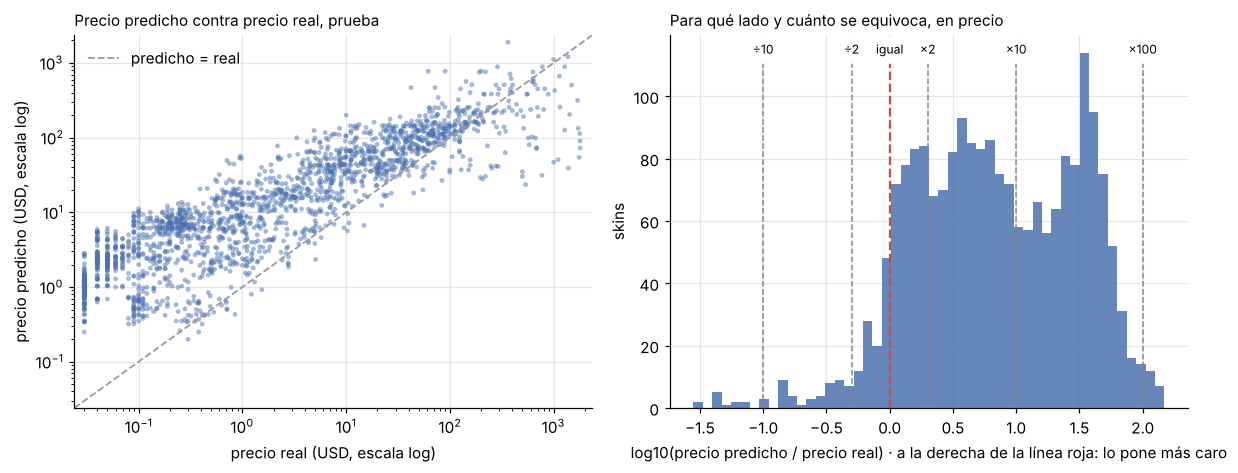

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].scatter(test["sell_price_usd"], test["precio_predicho_usd"], s=10, alpha=0.5,
              color=AZUL, edgecolors="none")
lim = [min(test["sell_price_usd"].min(), test["precio_predicho_usd"].min()) * 0.8,
       max(test["sell_price_usd"].max(), test["precio_predicho_usd"].max()) * 1.25]
ax[0].plot(lim, lim, color=GRIS, lw=1.2, ls="--", label="predicho = real")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("precio real (USD, escala log)"); ax[0].set_ylabel("precio predicho (USD, escala log)")
ax[0].set_title("Precio predicho contra precio real, prueba", loc="left", fontsize=10)
ax[0].legend(loc="upper left", frameon=False)

razon = np.log10(test["precio_predicho_usd"] / test["sell_price_usd"])
ax[1].hist(razon, bins=50, color=AZUL, alpha=0.85)
for x, etiqueta in [(-1, "÷10"), (np.log10(0.5), "÷2"), (0, "igual"), (np.log10(2), "×2"), (1, "×10"), (2, "×100")]:
    ax[1].axvline(x, color=ROJO if x == 0 else "#888888", lw=1 if x else 1.5, ls="--")
    ax[1].text(x, ax[1].get_ylim()[1] * 0.95, etiqueta, ha="center", fontsize=8,
               backgroundcolor="white")
ax[1].set_xlabel("log10(precio predicho / precio real) · a la derecha de la línea roja: lo pone más caro")
ax[1].set_ylabel("skins")
ax[1].set_title("Para qué lado y cuánto se equivoca, en precio", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

### 10.4 · Los errores más grandes

In [30]:
cols_ver = ["market_hash_name", "collection", "rarity", "wear", "origen",
            "percentil", "predicho", "error", "sell_price_usd", "precio_predicho_usd", "error_usd"]
peores = test.reindex(test["error"].abs().sort_values(ascending=False).index)[cols_ver].head(10)
peores.round(2)

,market_hash_name,collection,rarity,wear,origen,percentil,predicho,error,sell_price_usd,precio_predicho_usd,error_usd
1051,M4A4 | Sheet Lightning (Battle-Scarred),The Boreal Collection,Restricted,Battle-Scarred,drop de mapa,21.20,81.53,60.33,0.71,49.46,48.75
1050,M4A4 | Sheet Lightning (Well-Worn),The Boreal Collection,Restricted,Well-Worn,drop de mapa,21.77,80.85,59.08,0.75,44.99,44.24
413,Desert Eagle | Mulberry (Battle-Scarred),The Radiant Collection,Restricted,Battle-Scarred,drop de mapa,24.70,83.02,58.32,0.96,56.65,55.69
377,Desert Eagle | Firebreathing (Well-Worn),The Dead Hand Collection,Restricted,Well-Worn,drop de mapa,24.39,82.44,58.05,0.94,53.28,52.34
2016,XM1014 | Copperflage (Factory New),The Boreal Collection,Mil-Spec Grade,Factory New,drop de mapa,13.32,71.37,58.05,0.39,20.54,20.15
767,Glock-18 | Teal Graf (Factory New),The Overpass 2024 Collection,Mil-Spec Grade,Factory New,drop de mapa,18.97,76.82,57.85,0.60,31.99,31.39
1049,M4A4 | Sheet Lightning (Field-Tested),The Boreal Collection,Restricted,Field-Tested,drop de mapa,22.97,80.58,57.61,0.83,44.25,43.42
953,M4A4 | Zubastick (Battle-Scarred),The Dead Hand Collection,Mil-Spec Grade,Battle-Scarred,drop de mapa,4.69,62.10,57.41,0.10,11.15,11.05
376,Desert Eagle | Firebreathing (Field-Tested),The Dead Hand Collection,Restricted,Field-Tested,drop de mapa,25.03,82.32,57.30,0.98,52.57,51.59
1099,MAC-10 | Cat Fight (Battle-Scarred),The Genesis Collection,Restricted,Battle-Scarred,drop de mapa,17.95,74.99,57.04,0.55,27.21,26.66


### Dos errores concretos, explicados desde el dominio

Lo que más mueve el precio —qué diseño es, si es popular, si lo usan los
jugadores profesionales— no está en ninguna columna. El modelo sólo sabe la
rareza, el arma, el exterior, si es StatTrak o souvenir, de dónde sale y qué tan
difícil es sacarlo de una caja. Los errores van en sentidos opuestos, y cada uno
tiene su explicación.

**Desert Eagle | Mulberry (Battle-Scarred), The Radiant Collection.** Restricted,
"drop de mapa". El modelo lo puso en el percentil 83; está en el 25. En dólares:
vale 0,96 USD y el modelo predice **56,65 USD**, un error de +55,69. Para el modelo es
una combinación cara: rareza Restricted, una Desert Eagle y "drop de mapa", que en el
entrenamiento son colecciones viejas que ya no caen. Pero Radiant es una de las
colecciones del Armory (marzo de 2025): se consigue con el pase, hay mucha oferta y
vale menos de un dólar. Es la sección 9.1 en una sola fila. Los diez errores más
grandes de la tabla son todos así: "drop de mapa" de colecciones recientes, puestas
unos 57 a 60 puntos más arriba.

**Souvenir MAC-10 | Bronzer (Battle-Scarred), The Radiant Collection.** Consumer
Grade, souvenir "sin identificar". El modelo lo puso en el 76; está en el 98. En
dólares: vale **499,99 USD** y el modelo predice 30,18, un error de −469,81. Es el error
al revés: para una suma de efectos, Consumer Grade y Battle-Scarred es de lo más
barato que hay. Gradient Boosting aprendió la combinación —souvenir "sin identificar"
quiere decir escasez— y lo sube mucho (la regresión lineal, con el snapshot del
15/10, lo ponía en el 34). Pero no alcanza: casi no existen copias de esa variante, y
el precio lo fija esa escasez puntual, que no está en ninguna columna.

### 10.5 · En qué se apoya

**Importancia por permutación** sobre la prueba, medida en **R²**: cuánto baja el R²
si se desordena una columna. Se mide sobre las columnas originales, no sobre las
columnas del one-hot, así cada arma no aparece por separado. Se mide una vez y
no se cambia nada después. Un valor cercano a cero o negativo quiere decir que, en
las colecciones nuevas, esa columna no ayuda.

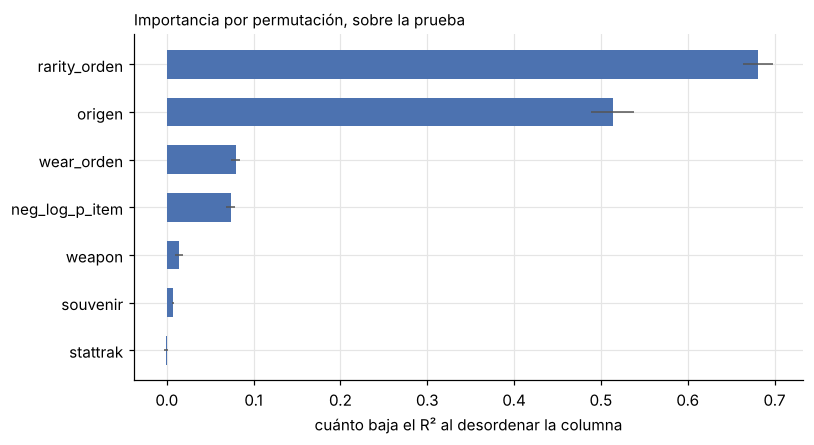

En la prueba, desordenar ['stattrak'] no baja el R²: en las colecciones nuevas esas columnas no ayudan. Lo que el modelo aprendió de ellas vale para el mercado establecido, no para el de las colecciones recién salidas (sección 9.1).


,columna,cuánto baja el R²,desvío
0,rarity_orden,0.681,0.017
5,origen,0.514,0.025
1,wear_orden,0.079,0.005
6,neg_log_p_item,0.074,0.005
4,weapon,0.014,0.004
3,souvenir,0.007,0.001
2,stattrak,-0.001,0.002


In [31]:
imp = permutation_importance(modelo_final, X_te[COLUMNAS_FINALES], y_te,
                             scoring="r2", n_repeats=20, random_state=SEMILLA)
importancia = (pd.DataFrame({"columna": COLUMNAS_FINALES,
                             "cuánto baja el R²": imp.importances_mean,
                             "desvío": imp.importances_std})
                 .sort_values("cuánto baja el R²", ascending=False))

fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(importancia) + 1))
orden = importancia.iloc[::-1]
ax.barh(orden["columna"], orden["cuánto baja el R²"], xerr=orden["desvío"],
        color=AZUL, height=0.6, error_kw={"ecolor": "#555555", "elinewidth": 1})
ax.set_xlabel("cuánto baja el R² al desordenar la columna")
ax.set_title("Importancia por permutación, sobre la prueba", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
no_ayudan = importancia.loc[importancia["cuánto baja el R²"] <= 0, "columna"].tolist()
if no_ayudan:
    print(f"En la prueba, desordenar {no_ayudan} no baja el R²: en las colecciones nuevas "
          "esas columnas no ayudan. Lo que el modelo aprendió de ellas vale para el mercado "
          "establecido, no para el de las colecciones recién salidas (sección 9.1).")
importancia.round(3)

**Los coeficientes, con su signo.** Si el elegido es la regresión lineal, son
los coeficientes del modelo final. Si es otro, se muestran los de la regresión
lineal ajustada con las mismas columnas, **como referencia de dirección**: no
son los del modelo final. Las columnas numéricas están escaladas, así que el
coeficiente es "cuántos puntos de percentil por cada desvío".

Abajo se contrasta el signo de cada coeficiente con lo que midió la Entrega 2.
Un coeficiente se lee **a igualdad de las demás columnas**: si contradice una
hipótesis, casi siempre es porque falta la columna que explica la diferencia.

In [32]:
if ELEGIDO == "regresión lineal (Ridge)":
    lineal, origen_coef = modelo_final, "del modelo final"
else:
    lineal = armar_modelo(Ridge(alpha=1.0), COLUMNAS_FINALES).fit(X_tr, y_tr)
    origen_coef = "de la regresión lineal de referencia (no del modelo final)"

pipe = lineal.regressor_
nombres = pipe.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({"columna": nombres, "coeficiente": pipe.named_steps["modelo"].coef_})
coef["columna"] = coef["columna"].str.replace(r"^[a-z_]+__", "", regex=True)
print("Coeficientes", origen_coef)
print("\nlos 8 que más suben el percentil:")
print(coef.sort_values("coeficiente", ascending=False).head(8).round(2).to_string(index=False))
print("\nlos 8 que más lo bajan:")
print(coef.sort_values("coeficiente").head(8).round(2).to_string(index=False))

# Signo esperado por las hipótesis de la Entrega 2
ESPERADO = {"rarity_orden": ("+", "más raro, más arriba"),
            "wear_orden": ("-", "H3: más gastado, más abajo"),
            "stattrak": ("+", "mismo skin en StatTrak, más arriba (d pareada 0,838)"),
            "souvenir": ("+", "H2: mismo skin en souvenir, más arriba")}
por_col = coef.set_index("columna")["coeficiente"]
contraste = pd.DataFrame([
    {"columna": c, "esperado": s, "por qué": motivo,
     "coeficiente": round(float(por_col[c]), 2),
     "coincide": (por_col[c] > 0) == (s == "+")}
    for c, (s, motivo) in ESPERADO.items() if c in por_col.index])
print("\ncontraste con la Entrega 2:")
print(contraste.to_string(index=False))
if contraste["coincide"].all():
    print("Todos los signos coinciden con lo que midió la Entrega 2.")
else:
    print("ATENCIÓN: hay signos que no coinciden; revisar qué columna falta.")

Coeficientes de la regresión lineal de referencia (no del modelo final)

los 8 que más suben el percentil:
                        columna  coeficiente
                   rarity_orden        17.60
         origen_sin identificar        15.88
missingindicator_neg_log_p_item         8.58
                   weapon_USP-S         6.98
                       souvenir         6.80
                    weapon_M4A4         6.48
                   weapon_AK-47         6.27
                 neg_log_p_item         6.05

los 8 que más lo bajan:
                columna  coeficiente
     weapon_R8 Revolver       -10.12
          weapon_MP5-SD        -9.60
origen_paquete souvenir        -9.08
               stattrak        -5.21
             wear_orden        -5.12
          weapon_UMP-45        -5.00
       weapon_Sawed-Off        -4.46
            origen_caja        -4.25

contraste con la Entrega 2:
     columna esperado                                              por qué  coeficiente  coincide
rar

**El signo de `stattrak`.** En la regresión lineal de referencia, el coeficiente de
`stattrak` sale negativo, al revés que la Entrega 2. No contradice la hipótesis:
un coeficiente lineal se lee *a igualdad de las demás columnas*, y StatTrak existe
casi sólo en los ítems de caja (que en el mercado establecido están más abajo que
los de mapa viejos). La lineal no puede separar las dos cosas con una suma de
efectos. La pregunta se responde como en la Entrega 2, **en pares**: el mismo skin,
en el mismo exterior, con y sin StatTrak.

In [33]:
base = df["market_hash_name"].str.replace("StatTrak™ ", "", regex=False)
pct_dia = df["sell_price_usd"].rank(pct=True) * 100
con_st = pct_dia[df["stattrak"] == 1].groupby(base[df["stattrak"] == 1]).first()
sin_st = pct_dia[(df["stattrak"] == 0) & (df["souvenir"] == 0)].groupby(
    base[(df["stattrak"] == 0) & (df["souvenir"] == 0)]).first()
pares = pd.concat([con_st.rename("con StatTrak"), sin_st.rename("sin StatTrak")], axis=1, join="inner")
dif_st = pares["con StatTrak"] - pares["sin StatTrak"]
print(f"pares (mismo skin y exterior): {len(pares)}")
print(f"la versión StatTrak está más arriba en el {(dif_st > 0).mean():.0%} de los pares, "
      f"con una diferencia mediana de {dif_st.median():+.1f} puntos de percentil")
print("En pares, StatTrak sube el percentil: coincide con la Entrega 2.")
print("\nStatTrak según el origen (filas):")
print(df.groupby(["origen", "stattrak"]).size().unstack(fill_value=0).to_string())

pares (mismo skin y exterior): 2088
la versión StatTrak está más arriba en el 83% de los pares, con una diferencia mediana de +4.8 puntos de percentil
En pares, StatTrak sube el percentil: coincide con la Entrega 2.

StatTrak según el origen (filas):
stattrak             0     1
origen                      
caja              2473  2475
drop de mapa      2885   135
paquete souvenir  1176     0
sin identificar    859     0


### 10.6 · ¿La columna que más pesa es una fuga?

Si la columna que más pesa sorprende, hay que sospechar antes de festejar. Lo
esperable por las hipótesis de la Entrega 2 es la rareza, el arma, el exterior,
ser souvenir y el origen. Ninguna columna del modelo se calcula a partir del precio, y
todas existen el día que sale un skin nuevo (sección 2). El chequeo de abajo lo
confirma con el número.

In [34]:
ESPERABLES = {"rarity_orden", "weapon", "wear_orden", "souvenir", "stattrak", "origen"}
principal = importancia.iloc[0]["columna"]
print(f"la columna que más pesa: {principal}")
if principal in ESPERABLES:
    print("Es una de las esperables por las hipótesis de la Entrega 2.")
else:
    print("ATENCIÓN: no es una de las esperables. Revisar si contiene información del precio.")

# Una fuga casi siempre se ve como un número demasiado bueno.
if R2_TEST > 0.95:
    print("ATENCIÓN: un R² mayor a 0,95 es sospechosamente bueno para un modelo sin el diseño del skin.")
else:
    print(f"R² de prueba {R2_TEST:.2f}: un número razonable (nada sospechosamente alto) para un "
          "modelo que no ve el diseño del skin.")

# Control directo: ninguna columna del modelo puede estar fuertemente atada al precio por construcción.
for c in [x for x in COLUMNAS_FINALES if x in COL_ORDINALES + COL_PROB_DROP]:
    rho = train[c].corr(train["percentil"], method="spearman")
    print(f"  Spearman {c:16s} contra el percentil: {rho:+.2f}")

la columna que más pesa: rarity_orden
Es una de las esperables por las hipótesis de la Entrega 2.
R² de prueba 0.27: un número razonable (nada sospechosamente alto) para un modelo que no ve el diseño del skin.
  Spearman rarity_orden     contra el percentil: +0.51
  Spearman wear_orden       contra el percentil: -0.23
  Spearman neg_log_p_item   contra el percentil: +0.61


## 11 · Las respuestas a las preguntas de la consigna

La celda de abajo arma las respuestas con los números de esta corrida, para
tenerlas a mano en la defensa. Se guardan también en `respuestas_defensa.txt`.

In [35]:
mejora_piso = R2_CV - PISO["R²"]
r2_te = resultado_test.set_index("")["R²"]
d_el = next((d for d in duelos if d["retador"] == ELEGIDO), None)
if d_el is None:
    duelo_txt = (f"El mayor R² es el de {ELEGIDO}, o ningún modelo más complejo le gana a la "
                 "regresión lineal por más que el desvío de la diferencia: se queda el más simple.")
else:
    duelo_txt = (f"{ELEGIDO} tiene el mayor R² y le suma {d_el['R² que suma el retador']:.3f} a la regresión\n"
                 f"   lineal, con un desvío de la diferencia de {d_el['desvío de la diferencia']:.3f} "
                 f"(gana en {d_el['pedazos en que gana']} pedazos): supera el ruido.")
gana_piso_inf_te = R2_TEST > r2_te.iloc[1]
ajuste_txt = ("el ajuste de hiperparámetros: sube el R² por más que el desvío, pero por muy poco "
              f"({mejora_ajuste:+.3f} ± {p_ajuste['desvío dif']:.3f}); con R² la grilla prefiere "
              "squared_error (sección 8)." if mejora_ajuste > p_ajuste["desvío dif"] else
              "el ajuste de hiperparámetros: mejora un poco, dentro del ruido (sección 8).")
respuestas = f'''
1. POR QUÉ ESA MÉTRICA
   R²: qué parte de la variación del percentil explica el modelo (1 = perfecto, 0 = lo
   mismo que predecir el promedio). Responde la pregunta del problema, y como el
   percentil está repartido parejo entre 0 y 100, su escala es la misma en todos los
   pedazos y se compara contra el piso. Pesa más los errores grandes, que acá son los
   que importan, y también castiga el sesgo. Se acompaña con el MAE (puntos de
   percentil) y el sesgo, porque el R² no dice para qué lado va el error, y acá va.

2. CUÁNTO LE GANA AL PISO, Y SI ES MUCHO O POCO
   Validación cruzada: piso {PISO['R²']:.3f} -> modelo {R2_CV:.3f} ± {DESVIO_CV:.3f}
   ({mejora_piso:.3f} de R² más). Contra el mejor piso informado
   ({MEJOR_PISO['modelo'].replace('piso informado: ', '')}, {MEJOR_PISO['R²']:.3f}): {R2_CV - MEJOR_PISO['R²']:.3f} más.
   El modelo explica ~{100 * R2_CV:.0f} % de la variación en colecciones posteriores; la tabla
   dinámica de rareza y exterior explica ~{100 * MEJOR_PISO['R²']:.0f} %.
   Prueba: modelo {R2_TEST:.3f} | piso {r2_te.iloc[0]:.3f} | piso informado {r2_te.iloc[1]:.3f}. Sesgo {SESGO_TEST:+.1f}.
   En el mercado establecido, explicar ~60 % de la posición sin ver el diseño del skin
   alcanza para decir si un skin nuevo va a quedar entre los baratos, los del medio o
   los caros. Para las colecciones más nuevas no alcanza: el modelo las pone
   ~{SESGO_TEST:.0f} puntos más arriba, {'y en la prueba no le gana al piso informado' if not gana_piso_inf_te else 'aunque en la prueba le sigue ganando al piso informado'}.
   Es el resultado más importante de la entrega, y se explica en la sección 9.1.

3. POR QUÉ LA VALIDACIÓN SE ARMA ASÍ
   Por colección (las filas hermanas y los skins de una colección nunca quedan de
   los dos lados) y en el tiempo (se valida con colecciones posteriores, porque
   el modelo es para las que vienen). Al azar el R² saldría {optimismo:.3f} más alto,
   y el sesgo de {esquemas[-1]['sesgo']:+.1f} desaparecería del número (sección 6.2).

4. POR QUÉ ESE MODELO Y NO UNO MÁS COMPLEJO
   Regla: se queda el de mayor R² medio, siempre que le gane a la regresión lineal
   por más que el desvío de la diferencia, medida en pares sobre los mismos pedazos.
   {duelo_txt}
   Ajustado con una grilla de {len(grilla)} combinaciones, quedándose con el mayor R²
   (sección 8). Con el MAE la elección era la misma. No tiene coeficientes para leer,
   pero la importancia por permutación (sección 10.5) muestra que se apoya en las
   columnas esperables por la Entrega 2.

5. UN TRAMO DONDE ERRA MUCHO
   {por_tramo['MAE'].idxmax()} (MAE {por_tramo['MAE'].max():.1f} puntos): los skins baratos de las colecciones nuevas.
   En dólares es poco ({en_dolares.loc[por_tramo['MAE'].idxmax(), 'error_abs_mediano_usd']:.2f} USD mediano) pero enorme en proporción
   ({en_dolares.loc[por_tramo['MAE'].idxmax(), 'error_relativo_mediano_pct']:.0f} % del precio). Los dos casos concretos están en la sección 10.4.

6. LA COLUMNA QUE MÁS PESA Y POR QUÉ NO ES UNA FUGA
   {principal}: desordenarla baja el R² de la prueba en {importancia.iloc[0]['cuánto baja el R²']:.2f}. Es la esperable
   por la Entrega 2, existe el día que sale el skin y no se calcula a partir del
   precio. Ninguna columna del modelo sale del precio; sell_listings, la única
   atada a él, quedó afuera desde la Entrega 2. Y el R² no es sospechosamente alto.

EN DÓLARES (PRECIO PREDICHO CONTRA PRECIO REAL, PRUEBA)
   Error absoluto mediano {test['error_abs_usd'].median():.2f} USD, medio {test['error_abs_usd'].mean():.2f} USD.
   Error relativo mediano {100 * test['error_rel'].median():.0f} % del precio real; el {100 * (test['error_usd'] > 0).mean():.0f} % de los
   precios predichos es más caro que el real. R² sobre el log10 del precio: {R2_LOG_USD:.2f}.

LO QUE PROBAMOS Y NO ANDUVO
   - la regresión lineal: es la referencia, pero Gradient Boosting le gana por más
     que el desvío de la diferencia (sección 6).
   - antiguedad_col_dias: el R² no sube, se derrumba y se vuelve inestable, y con
     árboles tampoco corrige el sesgo, porque no pueden extrapolar a 0 días (sección 7).
   - weapon: sacarla da igual, dentro del ruido; se queda por H1 (sección 8).
   - {ajuste_txt}
   - árboles con una columna por categórica (lo que marcó el profesor): {RESUMEN_ARBOLES}; la
     primera pregunta del árbol es {RAIZ}, nunca el precio (sección 8.2).

PARA LA ENTREGA 4
   - El modelo de la aplicación se reentrena con todas las filas (sección 12).
   - Mostrar la predicción como un rango de precio, no como un número, y decir que
     para colecciones recién salidas tiende a sobreestimar.
   - Separar en el pipeline las colecciones del Armory de las de mapa viejas:
     hoy las dos son "drop de mapa", y en el mercado se comportan al revés
     (sección 9.1). Es un dato que existe el día que sale un skin.
   - Volver a probar la antigüedad de otra forma (por tramos, o con un modelo que
     pueda extrapolar): el sesgo positivo sigue siendo el problema principal.
'''
print(respuestas)


1. POR QUÉ ESA MÉTRICA
   R²: qué parte de la variación del percentil explica el modelo (1 = perfecto, 0 = lo
   mismo que predecir el promedio). Responde la pregunta del problema, y como el
   percentil está repartido parejo entre 0 y 100, su escala es la misma en todos los
   pedazos y se compara contra el piso. Pesa más los errores grandes, que acá son los
   que importan, y también castiga el sesgo. Se acompaña con el MAE (puntos de
   percentil) y el sesgo, porque el R² no dice para qué lado va el error, y acá va.

2. CUÁNTO LE GANA AL PISO, Y SI ES MUCHO O POCO
   Validación cruzada: piso -0.094 -> modelo 0.614 ± 0.103
   (0.708 de R² más). Contra el mejor piso informado
   (promedio por rareza y exterior, 0.348): 0.267 más.
   El modelo explica ~61 % de la variación en colecciones posteriores; la tabla
   dinámica de rareza y exterior explica ~35 %.
   Prueba: modelo 0.272 | piso -0.149 | piso informado 0.308. Sesgo +22.6.
   En el mercado establecido, explicar ~60 % de la posi

## 12 · Guardado para la Entrega 4

Se guardan dos modelos, los dos con el preprocesamiento, el modelo y el recorte
adentro:

- **`modelo_percentil_cs2_evaluado.joblib`**: el que se midió en la prueba,
  entrenado sólo con el entrenamiento. Es la evidencia de esta entrega.
- **`modelo_percentil_cs2.joblib`**: el de la aplicación. Mismas columnas, mismo
  modelo y mismos hiperparámetros, reentrenado con **todas** las filas (como se
  decidió en la sección 9, antes de mirar la prueba). Su percentil se mide contra
  el mercado completo del día.

Aparte van los precios de cada mercado de referencia, que la aplicación necesita
para traducir el percentil a dólares, y la tabla de la prueba con el precio real, el
predicho y el error de cada skin (`prueba_precio_predicho_vs_real.csv`). Para cargar
un modelo hace falta la misma versión de scikit-learn; queda anotada en el JSON.

In [36]:
# El modelo de la aplicación: mismas decisiones, todas las filas.
MERCADO_TOTAL = np.sort(df["sell_price_usd"].to_numpy(dtype=float))
y_todo = percentil_contra(df["sell_price_usd"], MERCADO_TOTAL)
modelo_app = clone(modelo_final).fit(df[COLUMNAS_X], y_todo)

joblib.dump(modelo_final, SALIDAS / "modelo_percentil_cs2_evaluado.joblib")
joblib.dump(modelo_app, SALIDAS / "modelo_percentil_cs2.joblib")
np.save(SALIDAS / "mercado_referencia_usd.npy", MERCADO_TOTAL)
np.save(SALIDAS / "mercado_entrenamiento_usd.npy", MERCADO)

metadatos = {
    "grupo": "5K10-13", "snapshot": SNAPSHOT, "semilla": SEMILLA,
    "scikit_learn": sklearn.__version__,
    "objetivo": "percentil del precio contra el mercado de referencia (0 a 100)",
    "metrica_de_eleccion": "R² (MAE y sesgo se reportan como lectura)",
    "columnas": COLUMNAS_FINALES, "modelo": ELEGIDO,
    "hiperparametros": {k.replace(P, ""): str(v) for k, v in busqueda.best_params_.items()},
    "validacion": (f"temporal por colección: {len(PEDAZOS)} pedazos hacia adelante, "
                   "entrenando con las colecciones anteriores y validando con las siguientes"),
    "prueba": f"{len(test)} filas, {test['collection'].nunique()} colecciones más nuevas",
    "r2_cv": round(R2_CV, 4), "desvio_r2_cv": round(DESVIO_CV, 4),
    "mae_cv": round(MAE_CV, 3), "sesgo_cv": round(SESGO_CV, 3),
    "r2_prueba": round(R2_TEST, 4), "mae_prueba": round(MAE_TEST, 3), "sesgo_prueba": round(SESGO_TEST, 3),
    "r2_piso_cv": round(PISO["R²"], 4),
    "prueba_en_dolares": {
        "error_abs_medio_usd": round(float(test["error_abs_usd"].mean()), 2),
        "error_abs_mediano_usd": round(float(test["error_abs_usd"].median()), 2),
        "error_relativo_mediano_pct": round(float(100 * test["error_rel"].median()), 1),
        "r2_log10_precio": round(float(R2_LOG_USD), 4),
    },
    "modelo_app": "modelo_percentil_cs2.joblib, reentrenado con todas las filas",
    "mercado_app": "mercado_referencia_usd.npy (todas las filas del snapshot)",
    "advertencia": ("en colecciones recién lanzadas el modelo tiende a sobreestimar el percentil "
                    f"(sesgo en la prueba {SESGO_TEST:+.1f} puntos)"),
}
(SALIDAS / "modelo_metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2),
                                               encoding="utf-8")
tabla(pisos + comparacion).to_csv(SALIDAS / "comparacion_modelos.csv", index=False)
ablacion.to_csv(SALIDAS / "columnas_probadas.csv", index=False)
combos.drop(columns="_sacar").to_csv(SALIDAS / "columnas_en_duda_combinaciones.csv", index=False)
arboles_codificacion.to_csv(SALIDAS / "arboles_una_columna_por_categorica.csv", index=False)
grilla.to_csv(SALIDAS / "grilla_hiperparametros.csv", index=False)
(test[["market_hash_name", "collection", "percentil", "predicho", "error",
       "sell_price_usd", "precio_predicho_usd", "error_usd", "error_rel"]]
     .to_csv(SALIDAS / "prueba_precio_predicho_vs_real.csv", index=False))
(SALIDAS / "respuestas_defensa.txt").write_text(respuestas, encoding="utf-8")

# Control: los modelos guardados se cargan y predicen lo mismo.
for nombre, original in [("modelo_percentil_cs2_evaluado.joblib", modelo_final),
                         ("modelo_percentil_cs2.joblib", modelo_app)]:
    cargado = joblib.load(SALIDAS / nombre)
    assert np.allclose(cargado.predict(X_te.head(20)), original.predict(X_te.head(20)))
for f in sorted(SALIDAS.iterdir()):
    print("guardado:", f.name)

guardado: arboles_una_columna_por_categorica.csv
guardado: columnas_en_duda_combinaciones.csv
guardado: columnas_probadas.csv
guardado: comparacion_modelos.csv
guardado: grilla_hiperparametros.csv
guardado: mercado_entrenamiento_usd.npy
guardado: mercado_referencia_usd.npy
guardado: modelo_metadatos.json
guardado: modelo_percentil_cs2.joblib
guardado: modelo_percentil_cs2_evaluado.joblib
guardado: prueba_precio_predicho_vs_real.csv
guardado: respuestas_defensa.txt
